# Swiss lakes – level, outflow and inflow: comparing three ways to measure a drought

Companion to `lake_levels_climatology.ipynb`. Everything here uses **FOEN (BAFU) gauges only**
([data.bafu.admin.ch](https://data.bafu.admin.ch/en/)): lake level `W` at the lake and discharge `Q` at the outlet.

For each lake system we compare three measures:

| Method | Quantity | What it tells |
|---|---|---|
| **A. Level** | lake water level $H$ | what people see at the shore – but damped by regulation |
| **B. Outflow** | discharge at the outlet $Q_{out}$ | what is passed downstream – reflects weir operation |
| **C. Inflow** | $Q_{in} = Q_{out} + \sum_i A_i\,dH_i/dt$ | what the catchment actually delivered (net of lake evaporation) |

A regulated lake can show a normal level (A) while its inflow (C) is at a record low: the operator simply reduced
the outflow (B). Only C is independent of regulation.

Data are shared with the first notebook through the cache in `data/` (CSV per station and parameter).

In [1]:
import json
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from datetime import date, datetime, timezone
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy.stats import spearmanr

ENDPOINT = "https://data.bafu.admin.ch/api"
DATA_DIR = Path("data")
FIG_DIR = Path("figures") / "methods"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CURRENT_YEAR = date.today().year
CLIM_START_YEAR = 1970     # API daily data start in 1970
CLIM_END_YEAR = CURRENT_YEAR - 1
WINDOW_START = (7, 1)      # (month, day) start of the summer window; the window ends on the latest common day
MIN_COVERAGE = 0.9         # fraction of valid days required per year and window
SMOOTH_DAYS = 15           # centred smoothing of daily inflow (dH/dt of daily means is noisy: wind, seiches)
WINDOW_YEARS = 20          # API query window (20 years of daily values < 10 000 row cap)
MAX_WORKERS = 4
REF_YEAR = 2000            # leap reference year for day-of-year plots
REPORT_FIG_DIR = Path("figures") / "report"
REPORT_FIG_DIR.mkdir(parents=True, exist_ok=True)
# English names used on the report figures
SYS_EN = {"Lac Léman": "Lake Geneva", "Brienzersee": "Lake Brienz", "Thunersee": "Lake Thun",
          "Vierwaldstättersee": "Lake Lucerne", "Zugersee": "Lake Zug", "Walensee": "Walensee",
          "Zürichsee": "Lake Zurich", "Bodensee": "Lake Constance", "Sarnersee": "Lake Sarnen",
          "Lago di Lugano": "Lake Lugano", "Jura lakes": "Jura lakes", "Upper Engadin lakes": "Engadin lakes"}
REPORT_END = pd.Timestamp("2026-09-28")  # freeze the analysis on this day (for the report); None = latest data

C_CUR, C_MEAN, C_STD, C_RANGE = "#d62728", "#1f4e79", "#6b9ac4", "#c9d9ea"
C_OUT, C_STORE = "#1f4e79", "#e8a33d"

In [2]:
# Report figures are also saved as "<name>_large.png" with all text enlarged (for the large font report)
import matplotlib
import matplotlib.figure as mfig

REPORT_FIGS = {"weather_2026.png", "unusualness_per_lake.png", "map_2026.png", "inflow_vs_glacier.png",
               "anomaly_lakes.png", "validation_silsersee.png", "geneva_zurich.png", "surface_temperature.png",
               "evaporation_map.png", "evaporation_share.png"}
LARGE_FONT_SCALE = 1.6
TICK_FONT_SCALE = 1.3      # tick labels grow less, to avoid crowded axes

if not hasattr(mfig.Figure, "_orig_savefig"):
    mfig.Figure._orig_savefig = mfig.Figure.savefig
    mfig.Figure._orig_tight_layout = mfig.Figure.tight_layout

def _tight_layout(self, *args, **kwargs):
    self._tight_kwargs = kwargs
    return mfig.Figure._orig_tight_layout(self, *args, **kwargs)

def _savefig(self, fname, *args, **kwargs):
    out = mfig.Figure._orig_savefig(self, fname, *args, **kwargs)
    path = Path(fname)
    if path.name in REPORT_FIGS:
        ticks = {id(t) for ax in self.axes for t in ax.get_xticklabels() + ax.get_yticklabels()}
        for t in self.findobj(matplotlib.text.Text):
            small = id(t) in ticks or isinstance(t, matplotlib.text.Annotation)   # ticks and point labels
            t.set_fontsize(t.get_fontsize() * (TICK_FONT_SCALE if small else LARGE_FONT_SCALE))
        if hasattr(self, "_tight_kwargs"):
            mfig.Figure._orig_tight_layout(self, **self._tight_kwargs)
        mfig.Figure._orig_savefig(self, path.with_name(path.stem + "_large" + path.suffix), *args,
                                  **{**kwargs, "bbox_inches": "tight"})
    return out

mfig.Figure.tight_layout = _tight_layout
mfig.Figure.savefig = _savefig

## Lake systems

Lake surface areas and the regulation flag come from the FOEN VECTOR25 lake layer (`ch.bafu.vec25-seen`, fields `seeflaeche_km2` and `reguliert`).

In [3]:
LAKES_URL = "https://api3.geo.admin.ch/rest/services/api/MapServer/identify"
LAKES_PATH = DATA_DIR / "ch_lakes_vec25.json"

def load_lake_layer():
    """FOEN VECTOR25 lake polygons (layer ch.bafu.vec25-seen) with area and regulation flag, cached."""
    if not LAKES_PATH.exists():
        feats, offset = [], 0
        while True:
            res = requests.get(LAKES_URL, timeout=120, params=dict(
                geometryType="esriGeometryEnvelope", geometry="5.8,45.7,10.6,47.9", sr=4326,
                imageDisplay="1000,1000,96", mapExtent="5.8,45.7,10.6,47.9", tolerance=0,
                layers="all:ch.bafu.vec25-seen", returnGeometry="true", geometryFormat="geojson",
                limit=50, offset=offset)).json().get("results", [])
            feats += res
            if len(res) < 50:
                break
            offset += 50
        LAKES_PATH.write_text(json.dumps(feats))
    return json.loads(LAKES_PATH.read_text())

lake_props = {}
for f in load_lake_layer():
    lake_props.setdefault(f["properties"]["name"], f["properties"])

# level station -> lake name in the FOEN VECTOR25 layer (area and regulation flag are taken from there)
VEC25 = {"2028": "Le Léman", "2023": "Brienzer See", "2093": "Thuner See", "2207": "Vierwaldstättersee",
         "2017": "Zuger See", "2118": "Walensee", "2209": "Zürichsee", "2032": "Bodensee", "2043": "Bodensee",
         "2168": "Sempacher See", "2088": "Sarnersee", "2021": "Lago di Lugano", "2154": "Lac de Neuchâtel",
         "2208": "Bieler See", "2004": "Lac de Morat", "2072": "Lej da Segl", "2073": "Lej da Silvaplauna",
         "2066": "Lej da S. Murezzan"}
UNTERSEE_KM2 = 62.9   # the layer gives Bodensee as a whole (541.2 km²); split Obersee / Untersee

def area(no):
    a = lake_props[VEC25[no]]["seeflaeche_km2"]
    return {"2032": a - UNTERSEE_KM2, "2043": UNTERSEE_KM2}.get(no, a)

# level: station used for method A; levels: stations whose storage change is summed; outflow: {discharge station: sign};
# glacier: CAMELS-CH gauge for glacier cover
_SYS = {
    "Lac Léman":           dict(level="2028", levels=["2028"], outflow={"2606": 1}, glacier="2028"),
    "Brienzersee":         dict(level="2023", levels=["2023"], outflow={"2457": 1}, glacier="2023"),
    "Thunersee":           dict(level="2093", levels=["2093"], outflow={"2030": 1}, glacier="2093"),
    "Vierwaldstättersee":  dict(level="2207", levels=["2207"], outflow={"2152": 1}, glacier="2207"),
    "Zugersee":            dict(level="2017", levels=["2017"], outflow={"2125": 1}, glacier="2017"),
    "Walensee":            dict(level="2118", levels=["2118"], outflow={"2104": 1}, glacier="2118"),
    # Limmat at Unterhard is below the Sihl confluence -> subtract the Sihl
    "Zürichsee":           dict(level="2209", levels=["2209"], outflow={"2099": 1, "2176": -1}, glacier="2209"),
    "Bodensee":            dict(level="2032", levels=["2032", "2043"], outflow={"2288": 1}, glacier="2043"),
    # Sempachersee left out: its summer net inflow is close to zero, so percentages of it are not meaningful
    "Sarnersee":           dict(level="2088", levels=["2088"], outflow={"2102": 1}, glacier="2088"),
    "Lago di Lugano":      dict(level="2021", levels=["2021"], outflow={"2167": 1}, glacier="2021"),
    "Jura lakes":          dict(level="2154", levels=["2154", "2208", "2004"], outflow={"2029": 1}, glacier="2208"),
    "Upper Engadin lakes": dict(level="2072", levels=["2072", "2073", "2066"], outflow={"2105": 1}, glacier="2066"),
}
SYSTEMS = {name: {**s, "levels": {no: area(no) for no in s["levels"]}} for name, s in _SYS.items()}

# regulation flag of the lake used for method A, from the FOEN layer
UNREGULATED = {name for name, s in SYSTEMS.items() if not lake_props[VEC25[s["level"]]]["reguliert"]}
print("unregulated (FOEN layer):", sorted(UNREGULATED))

camels = pd.concat([
    pd.read_csv(DATA_DIR / "camels_ch" / "CAMELS_CH_topographic_attributes.csv", comment="#",
                dtype={"gauge_id": str}, encoding="latin1").set_index("gauge_id")[["area"]],
    pd.read_csv(DATA_DIR / "camels_ch" / "CAMELS_CH_glacier_attributes.csv", comment="#",
                dtype={"gauge_id": str}).set_index("gauge_id")[["glac_area"]],
], axis=1)
glacier_pct = {name: 100 * camels.loc[s["glacier"], "glac_area"] / camels.loc[s["glacier"], "area"]
               for name, s in SYSTEMS.items()}
pd.DataFrame({"glacier %": pd.Series(glacier_pct).round(1),
              "lake area km²": {n: sum(s["levels"].values()) for n, s in SYSTEMS.items()},
              "regulated": {n: n not in UNREGULATED for n in SYSTEMS}}).sort_values("glacier %")


unregulated (FOEN layer): ['Bodensee', 'Sarnersee', 'Walensee']


,glacier %,lake area km²,regulated
Zugersee,0.0,38.30,True
Sarnersee,0.0,7.50,False
Lago di Lugano,0.0,48.70,True
Bodensee,0.4,541.20,False
Zürichsee,1.1,90.10,True
Walensee,2.0,24.10,False
Jura lakes,2.3,280.70,True
Vierwaldstättersee,3.3,113.60,True
Upper Engadin lakes,4.2,8.08,True
Thunersee,7.7,48.40,True


## Download (cached) daily means of level W and discharge Q

In [4]:
QUERY = """
query ($no: String!, $param: String!, $from: AWSDateTime!, $to: AWSDateTime!) {
  water { observations {
    data_1day_mean(
      where: {station: {no: {_eq: $no}}, parameterName: {_eq: $param},
              timestamp: {_gte: $from, _lt: $to}},
      limit: 10000
    ) { timestamp value releaseState }
  } }
}
"""

def gql(query, variables, retries=5):
    for attempt in range(retries):
        try:
            r = requests.post(ENDPOINT, json={"query": query, "variables": variables}, timeout=120)
            if r.status_code in (403, 429, 500, 502, 503, 504):
                raise requests.HTTPError(f"HTTP {r.status_code}")
            payload = r.json()
            if payload.get("errors"):
                raise RuntimeError(payload["errors"])
            return payload["data"]["water"]["observations"]
        except (requests.RequestException, ValueError):
            if attempt == retries - 1:
                raise
            time.sleep(5 * 2 ** attempt)

def fmt(ts):
    return ts.strftime("%Y-%m-%dT%H:%M:%SZ")

def load(no, param):
    """Daily mean of `param` at station `no` (Series indexed by local date), cached in data/<param>_daily_<no>.csv."""
    path = DATA_DIR / f"{param}_daily_{no}.csv"
    end = pd.Timestamp(datetime.now(timezone.utc)).tz_localize(None) + pd.Timedelta(days=1)
    old = pd.read_csv(path, index_col="date", parse_dates=["date"]) if path.exists() else None
    cursor = old.index.max() - pd.Timedelta(days=30) if old is not None and len(old) else pd.Timestamp("1970-01-01")
    rows = []
    while cursor < end:
        nxt = min(cursor + pd.DateOffset(years=WINDOW_YEARS), end)
        rows += gql(QUERY, {"no": no, "param": param, "from": fmt(cursor), "to": fmt(nxt)})["data_1day_mean"]
        cursor = nxt
    df = old
    if rows:
        new = pd.DataFrame(rows)
        new["date"] = (pd.to_datetime(new["timestamp"], utc=True)
                       .dt.tz_convert("Europe/Zurich").dt.tz_localize(None).dt.normalize())
        new = new.drop(columns="timestamp").set_index("date")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", FutureWarning)
            df = new if old is None else pd.concat([old, new])
    df = df[~df.index.duplicated(keep="last")].sort_index()
    df.index.name = "date"
    df.to_csv(path)
    return df["value"]

jobs = sorted({(no, "W") for s in SYSTEMS.values() for no in s["levels"]} |
              {(no, "Q") for s in SYSTEMS.values() for no in s["outflow"]})
with ThreadPoolExecutor(MAX_WORKERS) as pool:
    DATA = dict(zip(jobs, pool.map(lambda j: load(*j), jobs)))
if REPORT_END is not None:
    DATA = {k: s[:REPORT_END] for k, s in DATA.items()}
print(f"{len(jobs)} series loaded; latest day: {min(s.index.max() for s in DATA.values()):%Y-%m-%d}")

/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44485/117010249.py:50: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = new if old is None else pd.concat([old, new])


30 series loaded; latest day: 2026-09-28


## Daily level, outflow and inflow per system

Storage change uses the day-to-day change of the daily mean level. Its daily noise (wind set-up, seiches, gauge
noise) is large for big lakes (1 cm/day on Lac Léman ≈ 67 m³/s), so daily inflow is smoothed over
`SMOOTH_DAYS` for plotting; window means are unaffected because they only depend on the net level change.

In [5]:
LAST_DAY = min(s.index.max() for s in DATA.values())
IDX = pd.date_range("1970-01-01", LAST_DAY, freq="D")

def system_daily(s):
    level = DATA[(s["level"], "W")].reindex(IDX)
    qout = sum(sign * DATA[(no, "Q")].reindex(IDX) for no, sign in s["outflow"].items())
    dstore = sum(area * 1e6 * DATA[(no, "W")].reindex(IDX).diff() for no, area in s["levels"].items()) / 86400
    return pd.DataFrame({"level": level, "qout": qout, "dstore": dstore, "qin": qout + dstore})

DAILY = {name: system_daily(s) for name, s in SYSTEMS.items()}

## Day-of-year climatology for the three methods

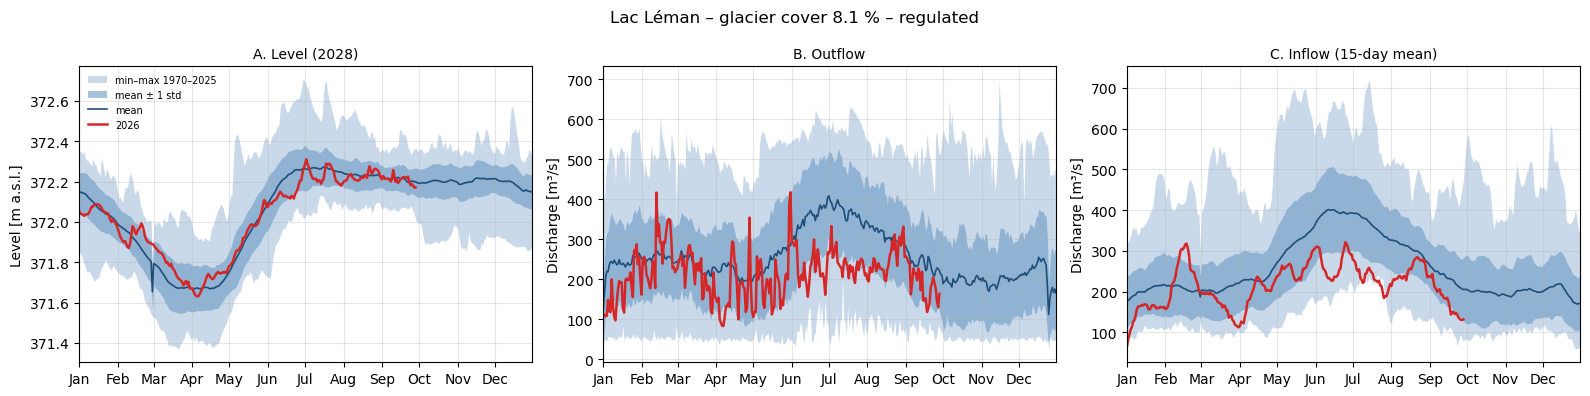

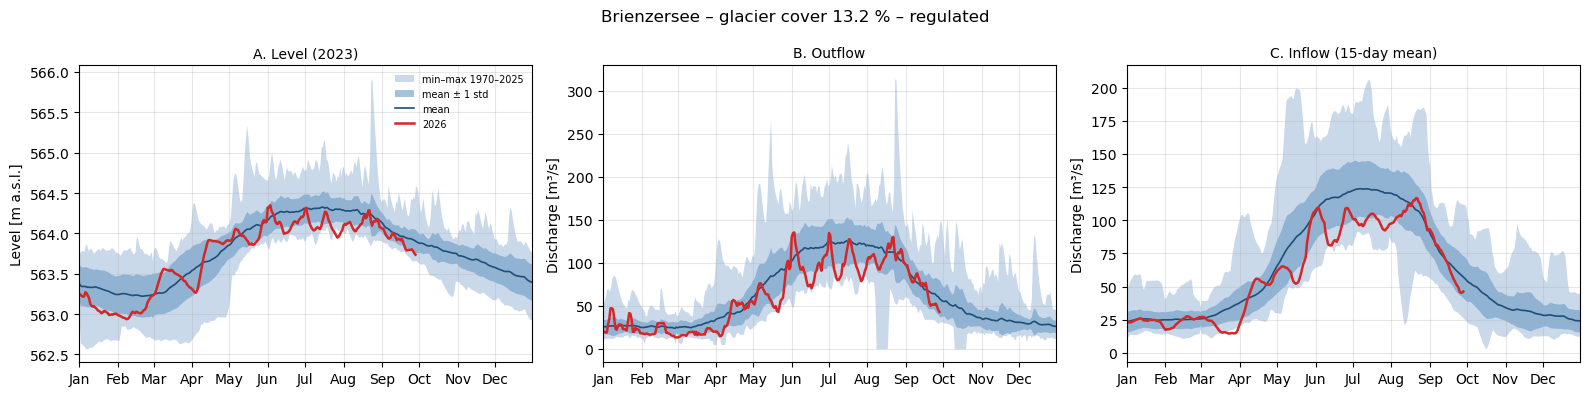

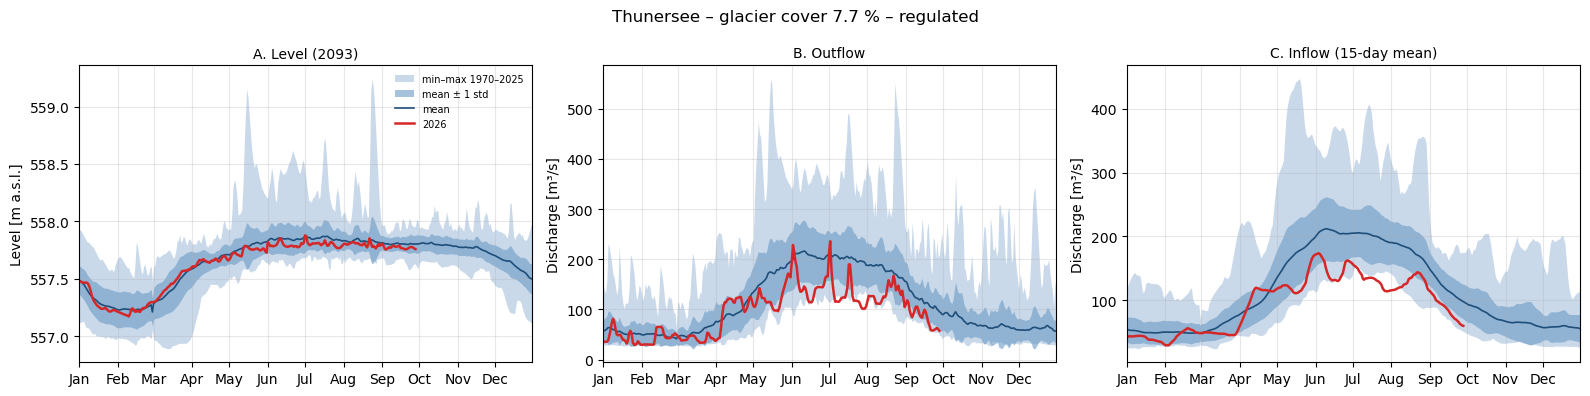

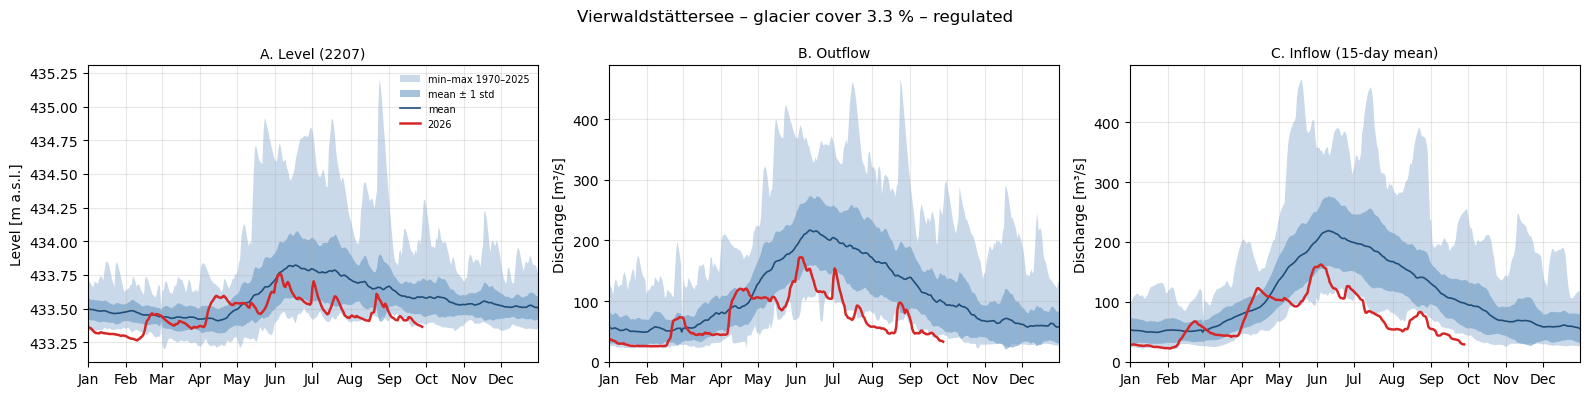

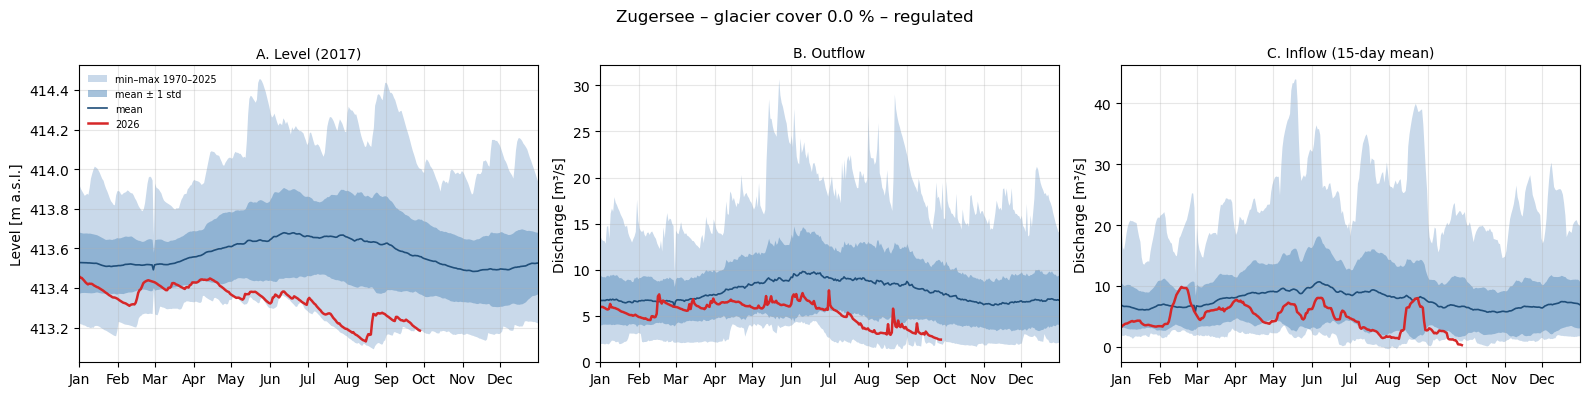

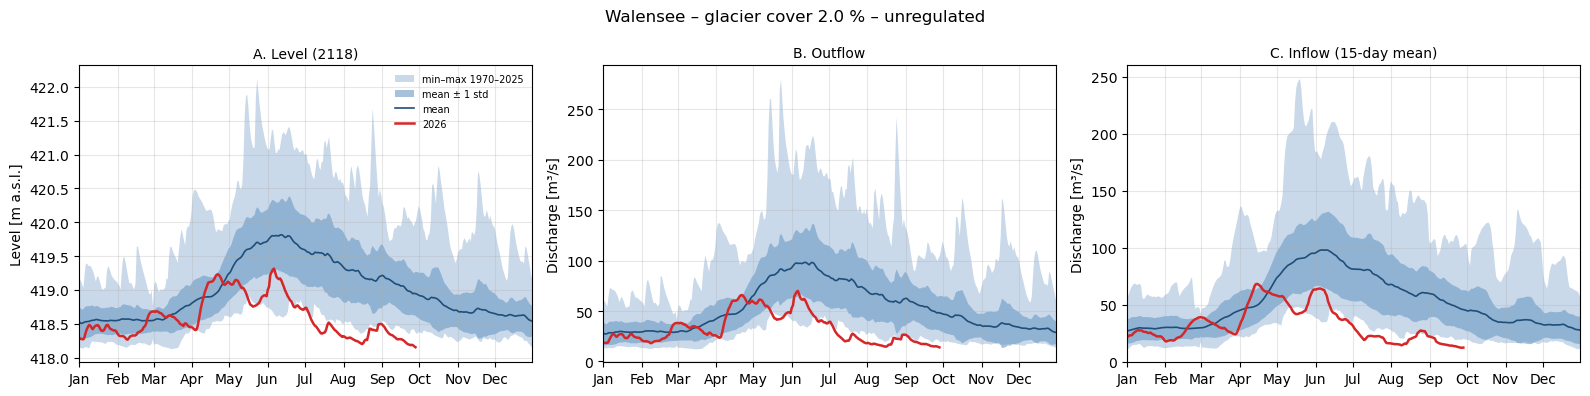

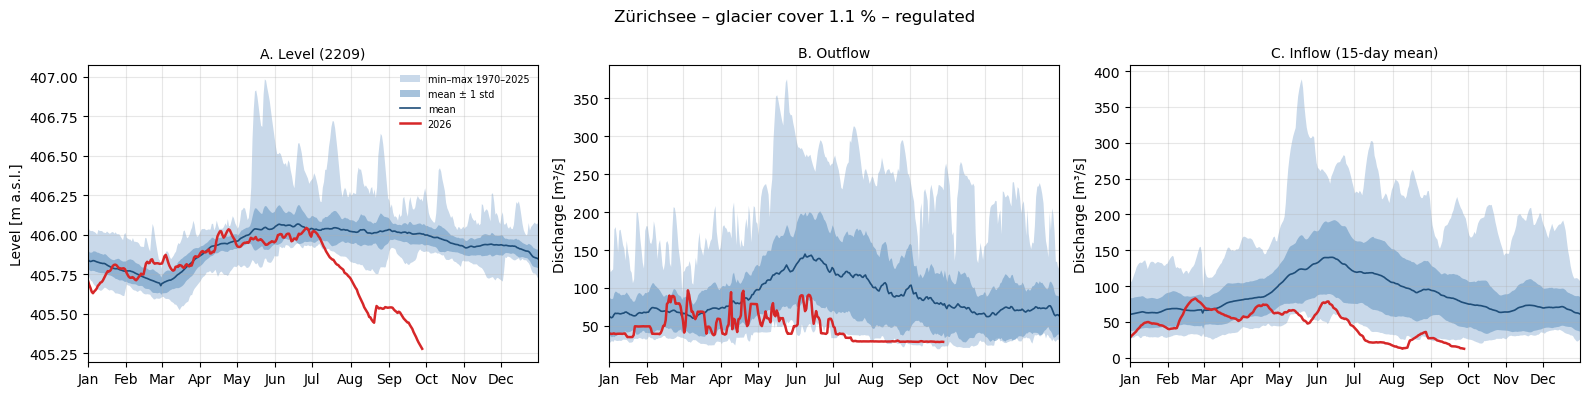

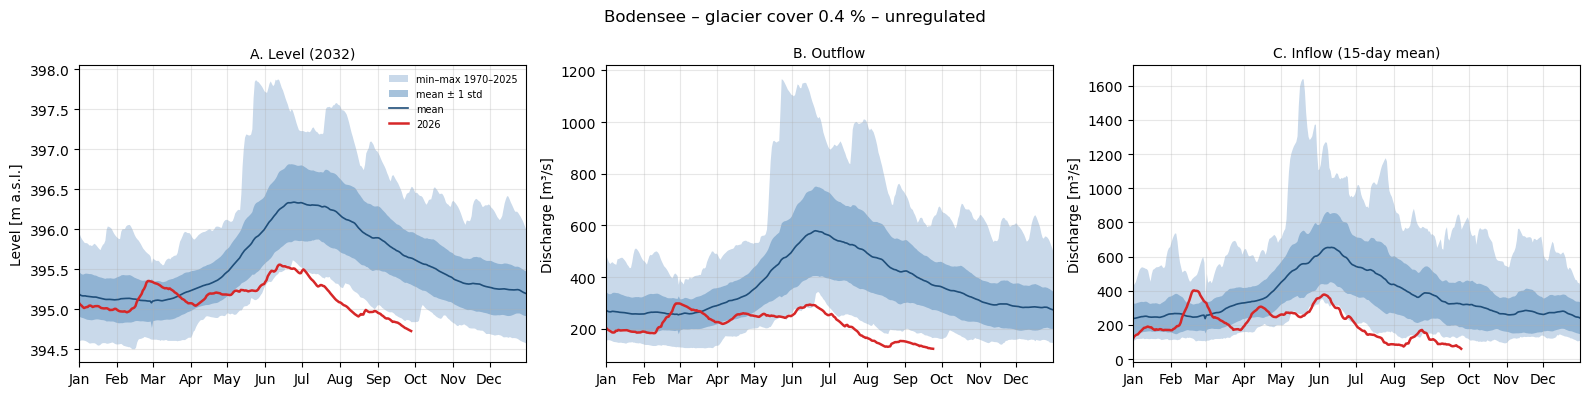

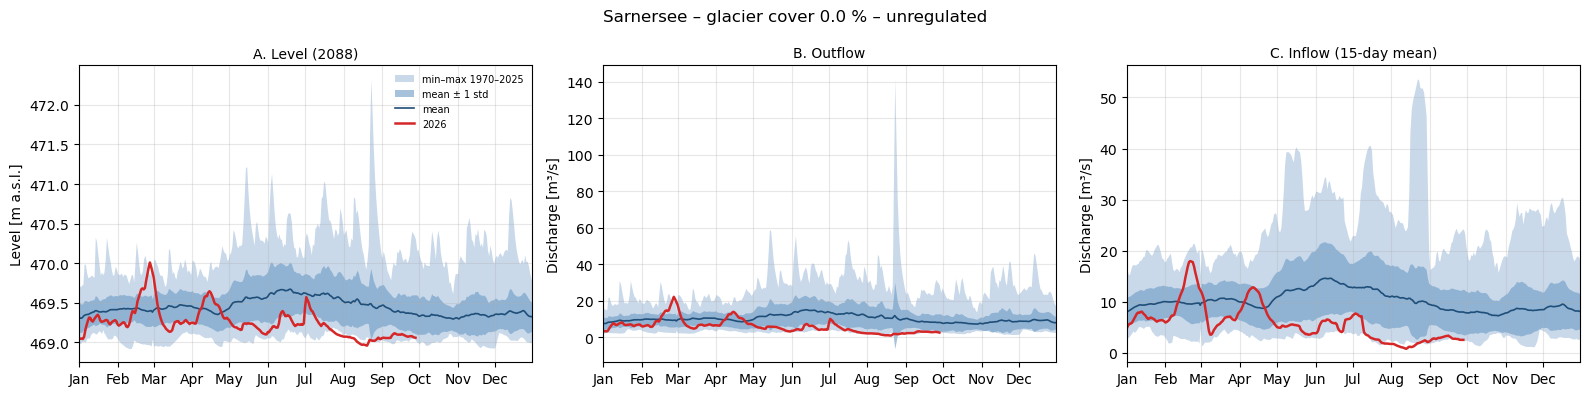

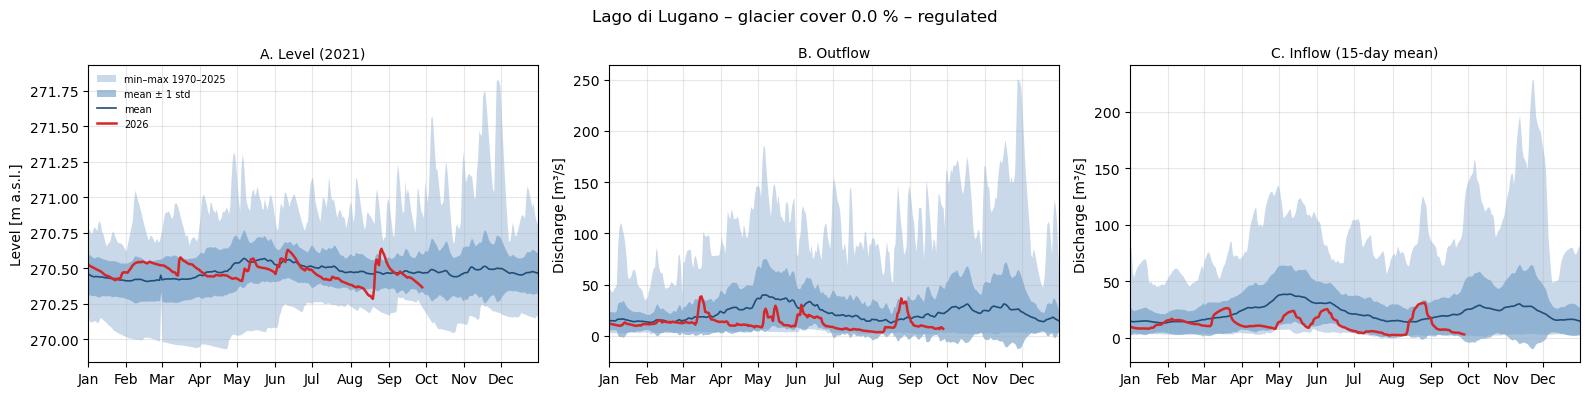

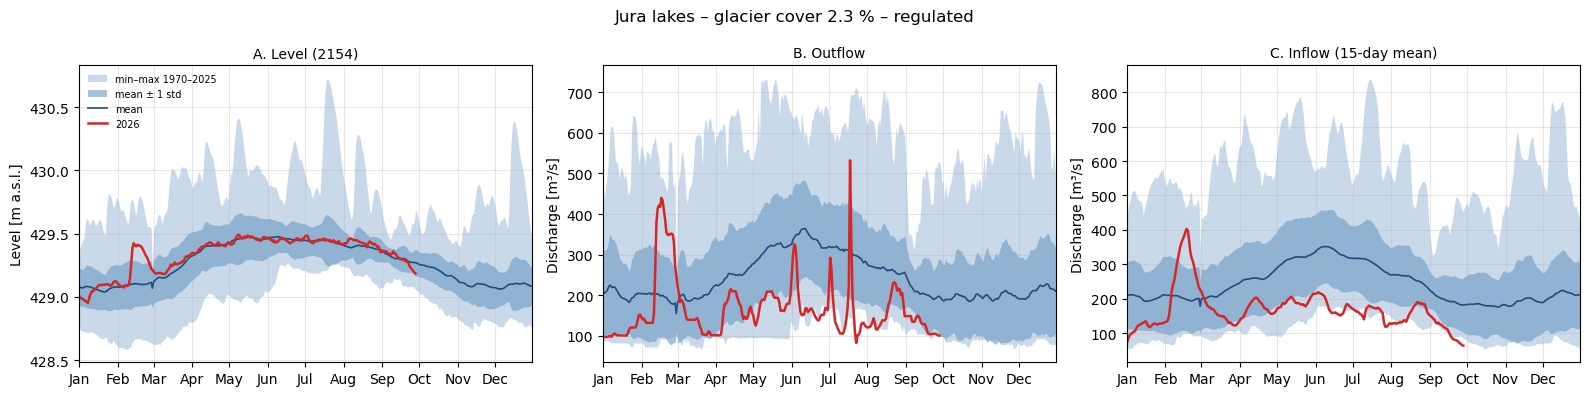

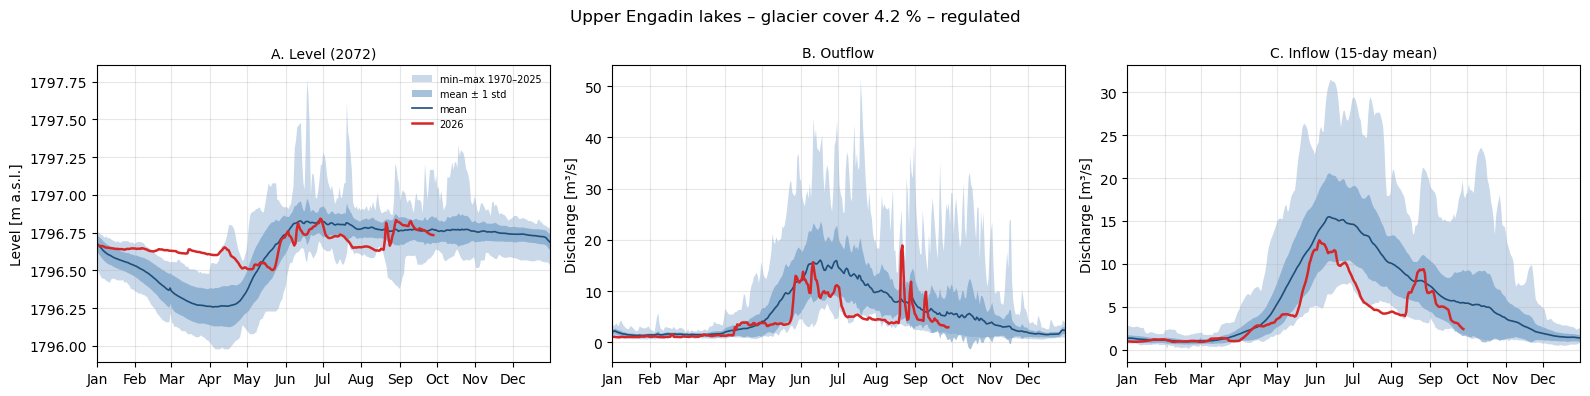

In [6]:
def to_ref(idx):
    return pd.DatetimeIndex(pd.to_datetime({"year": REF_YEAR, "month": idx.month, "day": idx.day}))

def climatology(s):
    ref = s[(s.index.year >= CLIM_START_YEAR) & (s.index.year <= CLIM_END_YEAR)].dropna()
    return ref.groupby(to_ref(ref.index)).agg(["mean", "std", "min", "max"])

def current(s):
    c = s[s.index.year == CURRENT_YEAR].dropna()
    return pd.Series(c.values, index=to_ref(c.index))

def plot_clim(ax, s, ylabel, title):
    clim = climatology(s)
    ax.fill_between(clim.index, clim["min"], clim["max"], color=C_RANGE, lw=0, label=f"min–max {CLIM_START_YEAR}–{CLIM_END_YEAR}")
    ax.fill_between(clim.index, clim["mean"] - clim["std"], clim["mean"] + clim["std"], color=C_STD, alpha=0.6,
                    lw=0, label="mean ± 1 std")
    ax.plot(clim.index, clim["mean"], color=C_MEAN, lw=1.2, label="mean")
    cur = current(s)
    ax.plot(cur.index, cur.values, color=C_CUR, lw=1.8, label=str(CURRENT_YEAR))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_xlim(pd.Timestamp(f"{REF_YEAR}-01-01"), pd.Timestamp(f"{REF_YEAR}-12-31"))
    ax.yaxis.get_major_formatter().set_useOffset(False)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)

for name, d in DAILY.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    plot_clim(axes[0], d["level"], "Level [m a.s.l.]", f"A. Level ({SYSTEMS[name]['level']})")
    plot_clim(axes[1], d["qout"], "Discharge [m³/s]", "B. Outflow")
    plot_clim(axes[2], d["qin"].rolling(SMOOTH_DAYS, center=True, min_periods=SMOOTH_DAYS // 2).mean(),
              "Discharge [m³/s]", f"C. Inflow ({SMOOTH_DAYS}-day mean)")
    axes[0].legend(fontsize=7, frameon=False, loc="best")
    fig.suptitle(f"{name} – glacier cover {glacier_pct[name]:.1f} %"
                 + (" – unregulated" if name in UNREGULATED else " – regulated"), fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name.replace(' ', '_')}.png", dpi=130)
    plt.show()

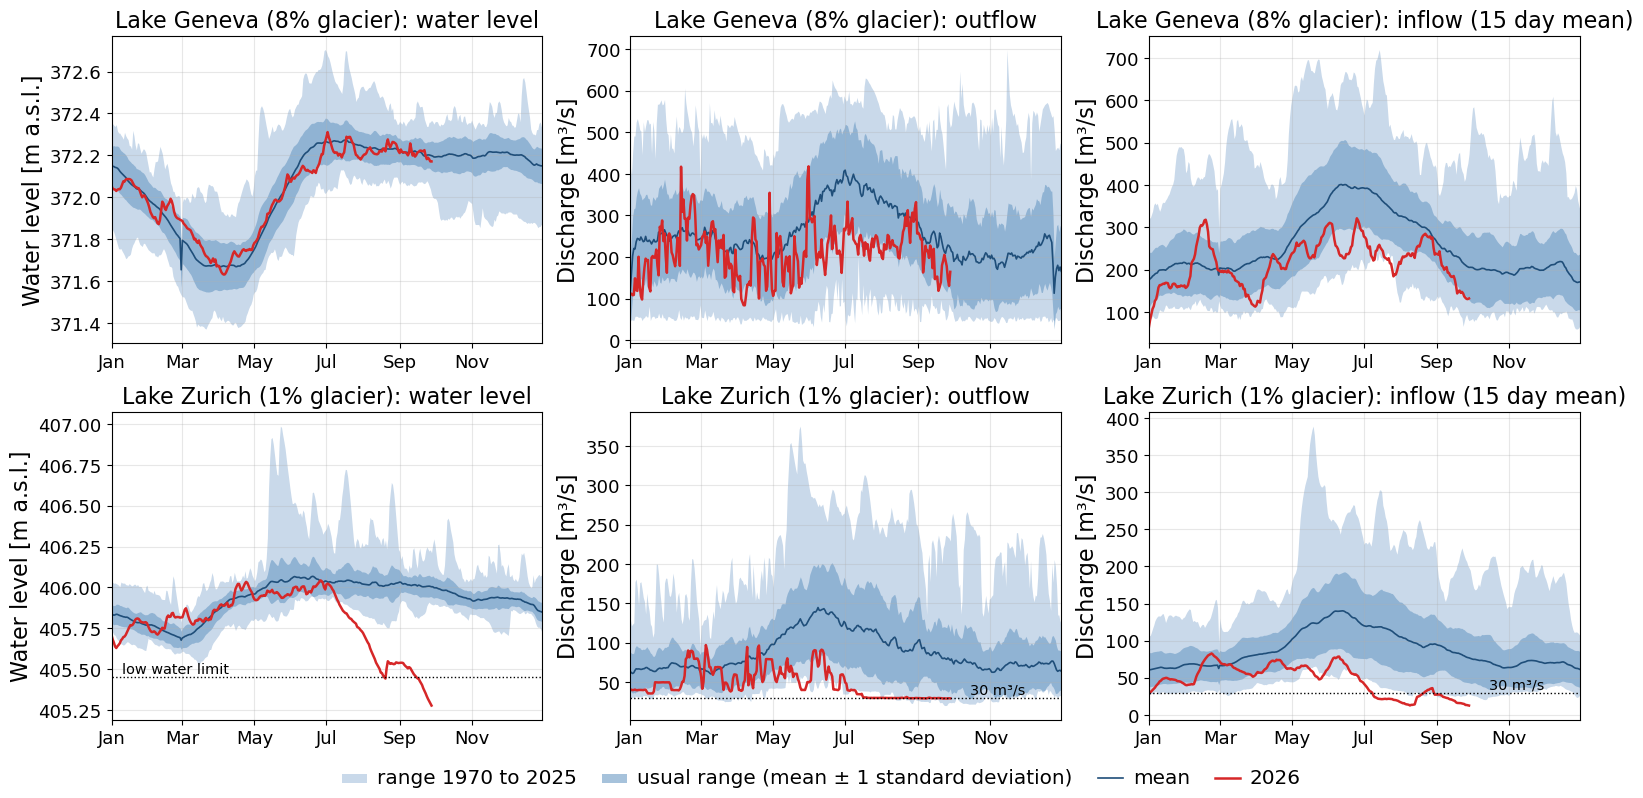

In [7]:
ZURICH_LOW_WATER = 405.45   # m a.s.l., low water limit ("Niedrigwassergrenze"), BAFU fact sheet 2014
ZURICH_MIN_OUT = 30         # m³/s, outflow held into the Limmat from mid July 2026

def band(ax, s, ylabel, title, legend=False):
    clim = climatology(s)
    ax.fill_between(clim.index, clim["min"], clim["max"], color=C_RANGE, lw=0,
                    label=f"range {CLIM_START_YEAR} to {CLIM_END_YEAR}")
    ax.fill_between(clim.index, clim["mean"] - clim["std"], clim["mean"] + clim["std"], color=C_STD, alpha=0.6,
                    lw=0, label="usual range (mean ± 1 standard deviation)")
    ax.plot(clim.index, clim["mean"], color=C_MEAN, lw=1.2, label="mean")
    cur = current(s)
    ax.plot(cur.index, cur.values, color=C_CUR, lw=1.8, label=str(CURRENT_YEAR))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 3, 5, 7, 9, 11]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_xlim(pd.Timestamp(f"{REF_YEAR}-01-01"), pd.Timestamp(f"{REF_YEAR}-12-31"))
    ax.yaxis.get_major_formatter().set_useOffset(False)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for row, name in enumerate(["Lac Léman", "Zürichsee"]):
    d = DAILY[name]
    lab = f"{SYS_EN[name]} ({glacier_pct[name]:.0f}% glacier)"
    band(axes[row, 0], d["level"], "Water level [m a.s.l.]", f"{lab}: water level")
    band(axes[row, 1], d["qout"], "Discharge [m³/s]", f"{lab}: outflow")
    band(axes[row, 2], d["qin"].rolling(SMOOTH_DAYS, center=True, min_periods=SMOOTH_DAYS // 2).mean(),
         "Discharge [m³/s]", f"{lab}: inflow ({SMOOTH_DAYS} day mean)")
axes[1, 0].axhline(ZURICH_LOW_WATER, color="k", ls=":", lw=1)
axes[1, 0].annotate("low water limit", (pd.Timestamp(f"{REF_YEAR}-01-10"), ZURICH_LOW_WATER), xytext=(0, 3),
                    textcoords="offset points", fontsize=8)
for ax in axes[1, 1:]:
    ax.axhline(ZURICH_MIN_OUT, color="k", ls=":", lw=1)
    ax.annotate(f"{ZURICH_MIN_OUT} m³/s", (pd.Timestamp(f"{REF_YEAR}-10-15"), ZURICH_MIN_OUT), xytext=(0, 3),
                textcoords="offset points", fontsize=8)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="lower center", ncol=4, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(REPORT_FIG_DIR / "geneva_zurich.png", dpi=150)
plt.show()

## Summer window: how unusual is the current year by each method?

For every year the mean over the summer window (1 July → latest day) is computed for level, outflow and inflow.
The current year is expressed as anomaly (z against 1970–2025), percent of normal (discharges) and rank
from the lowest (1 = lowest since 1970).

In [8]:
m0, d0 = WINDOW_START

def window_means(d):
    out = {}
    for y in range(1970, CURRENT_YEAR + 1):
        a, b = pd.Timestamp(y, m0, d0), pd.Timestamp(y, LAST_DAY.month, LAST_DAY.day)
        w = d.loc[a:b]
        n = (b - a).days + 1
        if w["qin"].notna().sum() >= MIN_COVERAGE * n and w["level"].notna().sum() >= MIN_COVERAGE * n:
            out[y] = w.mean()
    return pd.DataFrame(out).T

WIN = {name: window_means(d) for name, d in DAILY.items()}

rows = []
for name, wm in WIN.items():
    if CURRENT_YEAR not in wm.index:
        print(f"{name}: no complete {CURRENT_YEAR} window")
        continue
    ref = wm.loc[CLIM_START_YEAR:CLIM_END_YEAR]
    cur = wm.loc[CURRENT_YEAR]
    row = {"system": name, "glacier_pct": glacier_pct[name], "regulated": name not in UNREGULATED,
           "n_years": len(wm)}
    for col, key in [("level", "level"), ("qout", "outflow"), ("qin", "inflow")]:
        row[f"z_{key}"] = (cur[col] - ref[col].mean()) / ref[col].std()
        row[f"rank_{key}"] = int((wm[col] <= cur[col]).sum())
    row["level_anom_cm"] = 100 * (cur["level"] - ref["level"].mean())
    row["outflow_pct"] = 100 * cur["qout"] / ref["qout"].mean()
    row["inflow_pct"] = 100 * cur["qin"] / ref["qin"].mean()
    rows.append(row)
comp = pd.DataFrame(rows).set_index("system").sort_values("inflow_pct")
print(f"Window {m0:02d}-{d0:02d} → {LAST_DAY:%m-%d}")
comp.round(2)

Window 07-01 → 09-28


,glacier_pct,regulated,n_years,z_level,rank_level,z_outflow,rank_outflow,z_inflow,rank_inflow,level_anom_cm,outflow_pct,inflow_pct
system,,,,,,,,,,,,
Zürichsee,1.15,True,57,-8.87,1,-2.58,1,-2.90,1,-39.30,30.94,22.82
Sarnersee,0.00,False,53,-2.70,1,-2.57,1,-2.51,1,-37.89,28.14,27.43
Bodensee,0.42,False,57,-2.86,1,-2.78,1,-2.93,1,-98.15,36.17,28.29
Walensee,1.97,False,57,-3.18,1,-2.86,1,-2.95,1,-91.25,31.72,30.02
Zugersee,0.00,True,57,-2.24,2,-1.70,3,-1.49,4,-39.59,45.32,40.22
Vierwaldstättersee,3.28,True,57,-2.20,2,-2.85,1,-2.98,1,-20.79,44.21,43.39
Lago di Lugano,0.00,True,57,-0.74,11,-1.00,12,-1.06,12,-4.78,54.30,50.76
Jura lakes,2.31,True,57,0.16,38,-1.90,1,-2.03,1,1.16,58.43,55.94
Upper Engadin lakes,4.24,True,57,-1.57,5,-1.81,3,-1.85,3,-5.76,58.91,58.26


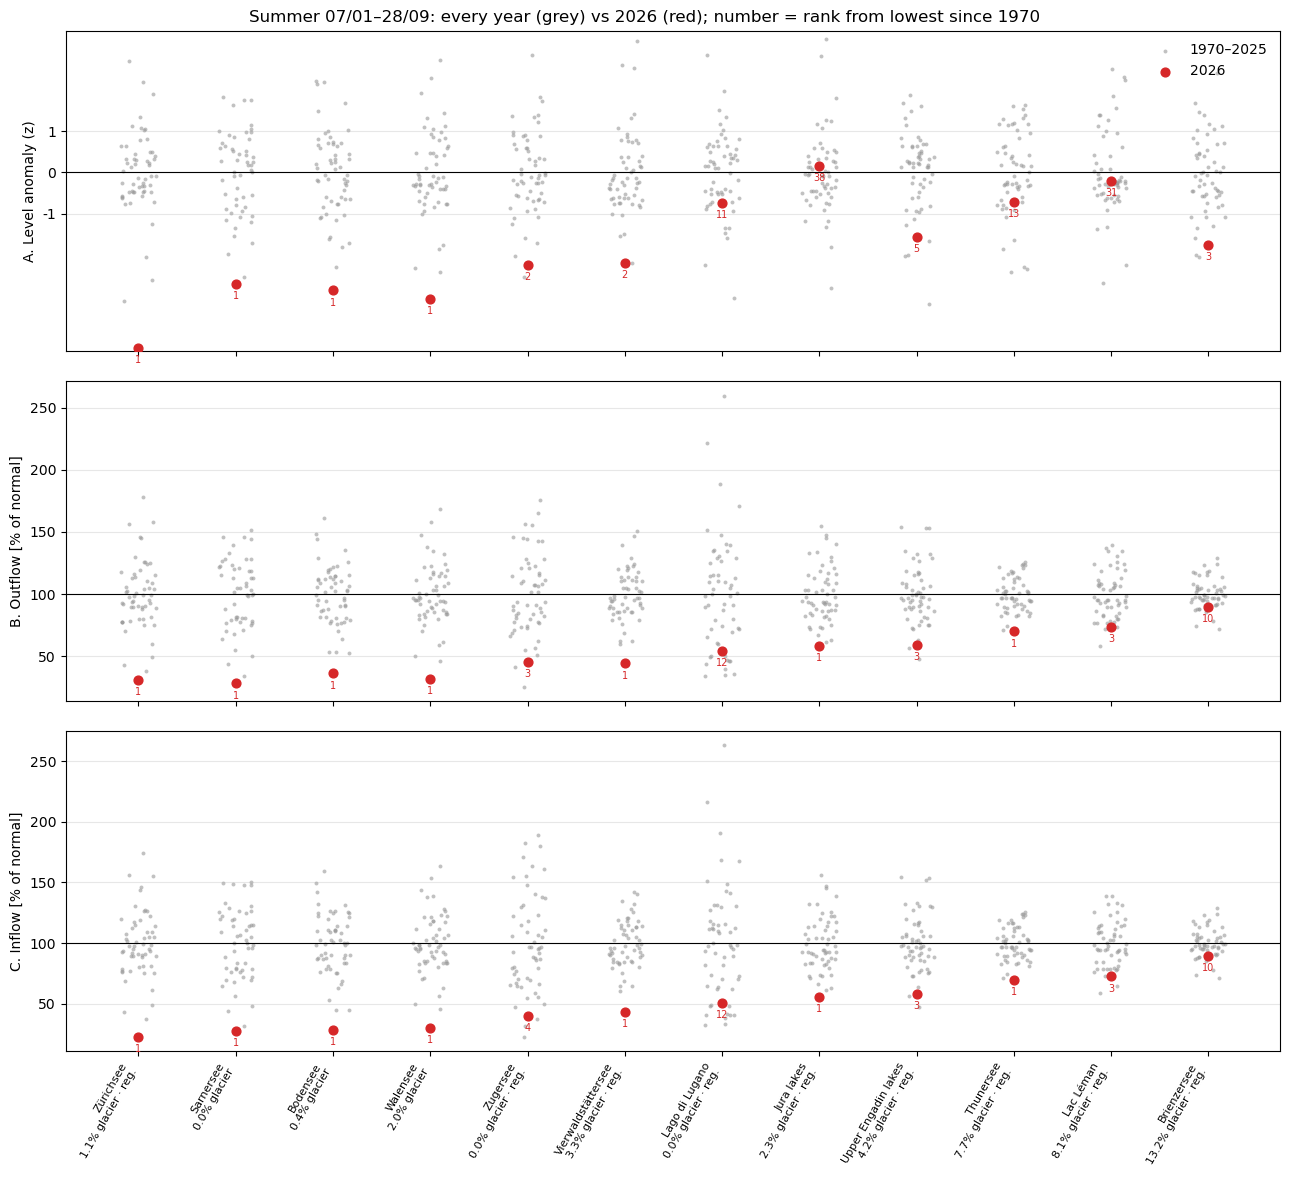

In [9]:
def strip(ax, col_values, cur_values, ranks, n_years, order, ylabel, ref_line):
    rng = np.random.default_rng(0)
    for i, name in enumerate(order):
        past = col_values[name]
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(past)), past, s=8, color="0.6", alpha=0.6, lw=0,
                   label="1970–2025" if i == 0 else None)
        ax.scatter(i, cur_values[name], s=40, color=C_CUR, zorder=3, label=str(CURRENT_YEAR) if i == 0 else None)
        ax.annotate(f"{ranks[name]}", (i, cur_values[name]), xytext=(0, -11), textcoords="offset points",
                    ha="center", fontsize=7, color=C_CUR)
    ax.axhline(ref_line, color="k", lw=0.8)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)

order = comp.index
series_by_method = {}
for name in order:
    wm = WIN[name]
    ref = wm.loc[CLIM_START_YEAR:CLIM_END_YEAR]
    past = wm.loc[wm.index != CURRENT_YEAR]
    series_by_method.setdefault("level", {})[name] = (past["level"] - ref["level"].mean()) / ref["level"].std()
    series_by_method.setdefault("outflow", {})[name] = 100 * past["qout"] / ref["qout"].mean()
    series_by_method.setdefault("inflow", {})[name] = 100 * past["qin"] / ref["qin"].mean()

fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
strip(axes[0], series_by_method["level"], comp["z_level"], comp["rank_level"], comp["n_years"], order,
      "A. Level anomaly (z)", 0)
strip(axes[1], series_by_method["outflow"], comp["outflow_pct"], comp["rank_outflow"], comp["n_years"], order,
      "B. Outflow [% of normal]", 100)
strip(axes[2], series_by_method["inflow"], comp["inflow_pct"], comp["rank_inflow"], comp["n_years"], order,
      "C. Inflow [% of normal]", 100)
axes[0].set_yscale("symlog", linthresh=3)
axes[0].yaxis.set_major_formatter(plt.FormatStrFormatter("%g"))
axes[0].legend(frameon=False, loc="upper right")
labels = [f"{n}\n{glacier_pct[n]:.1f}% glacier" + ("" if n in UNREGULATED else " · reg.") for n in order]
axes[2].set_xticks(range(len(order)), labels, rotation=60, ha="right", fontsize=8)
fig.suptitle(f"Summer {m0:02d}/{d0:02d}–{LAST_DAY:%d/%m}: every year (grey) vs {CURRENT_YEAR} (red); "
             "number = rank from lowest since 1970", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "three_methods_strip.png", dpi=150)
plt.show()

## Do the methods agree?

If lake level were a good drought indicator, the level anomaly (A) would track the inflow anomaly (C).
Regulation breaks that link: operators first reduce outflow, so the level stays near normal until the outflow
cannot be reduced any further.

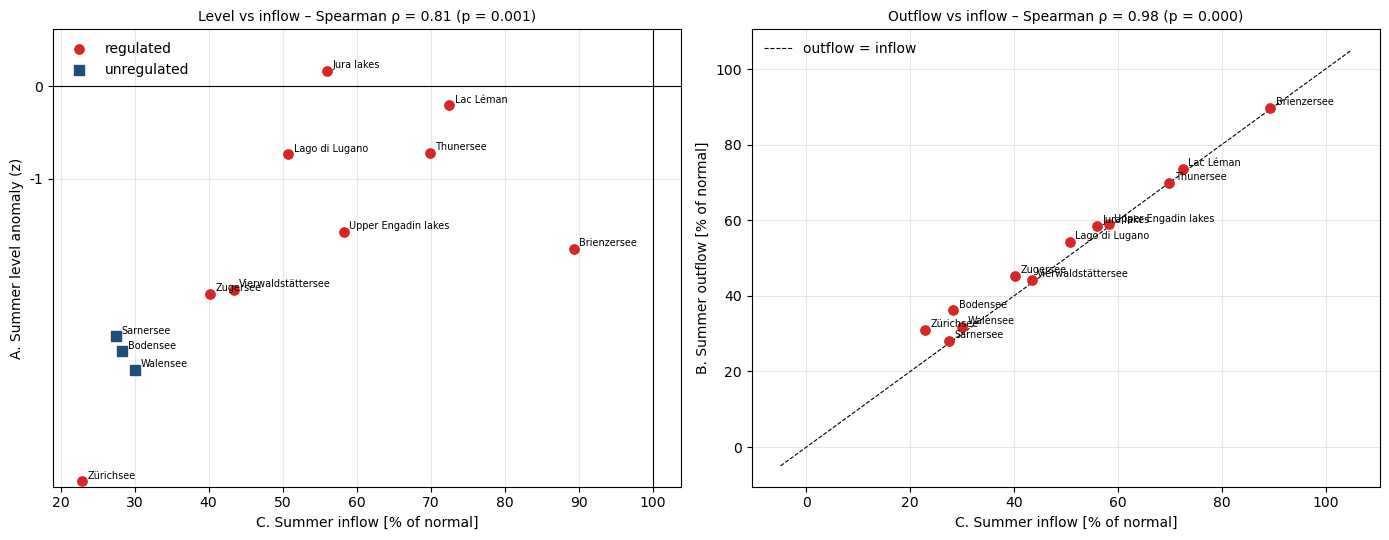

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
for reg, mk in [(True, "o"), (False, "s")]:
    d = comp[comp["regulated"] == reg]
    ax.scatter(d["inflow_pct"], d["z_level"], marker=mk, s=45, color=C_CUR if reg else C_MEAN, zorder=3,
               label="regulated" if reg else "unregulated")
for n, r in comp.iterrows():
    ax.annotate(n, (r["inflow_pct"], r["z_level"]), xytext=(4, 2), textcoords="offset points", fontsize=7)
rho, p = spearmanr(comp["inflow_pct"], comp["z_level"])
ax.axhline(0, color="k", lw=0.8)
ax.axvline(100, color="k", lw=0.8)
ax.set_yscale("symlog", linthresh=3)
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%g"))
ax.set_xlabel("C. Summer inflow [% of normal]")
ax.set_ylabel("A. Summer level anomaly (z)")
ax.set_title(f"Level vs inflow – Spearman ρ = {rho:.2f} (p = {p:.3f})", fontsize=10)
ax.legend(frameon=False)
ax.grid(alpha=0.3)

ax = axes[1]
ax.scatter(comp["inflow_pct"], comp["outflow_pct"], s=45, color=C_CUR, zorder=3)
for n, r in comp.iterrows():
    ax.annotate(n, (r["inflow_pct"], r["outflow_pct"]), xytext=(4, 2), textcoords="offset points", fontsize=7)
lim = [min(comp[["inflow_pct", "outflow_pct"]].min().min(), 0) - 5, 105]
ax.plot(lim, lim, "k--", lw=0.8, label="outflow = inflow")
rho, p = spearmanr(comp["inflow_pct"], comp["outflow_pct"])
ax.set_xlabel("C. Summer inflow [% of normal]")
ax.set_ylabel("B. Summer outflow [% of normal]")
ax.set_title(f"Outflow vs inflow – Spearman ρ = {rho:.2f} (p = {p:.3f})", fontsize=10)
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "methods_agreement.png", dpi=150)
plt.show()

## When did the lakes lose their water?

The level anomaly on the latest day is split into the anomaly already present on the first day of the summer window
(built up in winter/spring: low snowpack, dry spring) and the additional anomaly accumulated during the summer window.

Over the summer, almost all of the inflow deficit is passed downstream (see table): the flow through a lake is much
larger than its storage change. But for a lake that has reached its minimum outflow (e.g. Zürichsee, where the Limmat
has been held at a constant low flow since mid-July), even the small remaining share translates into a large level drop.

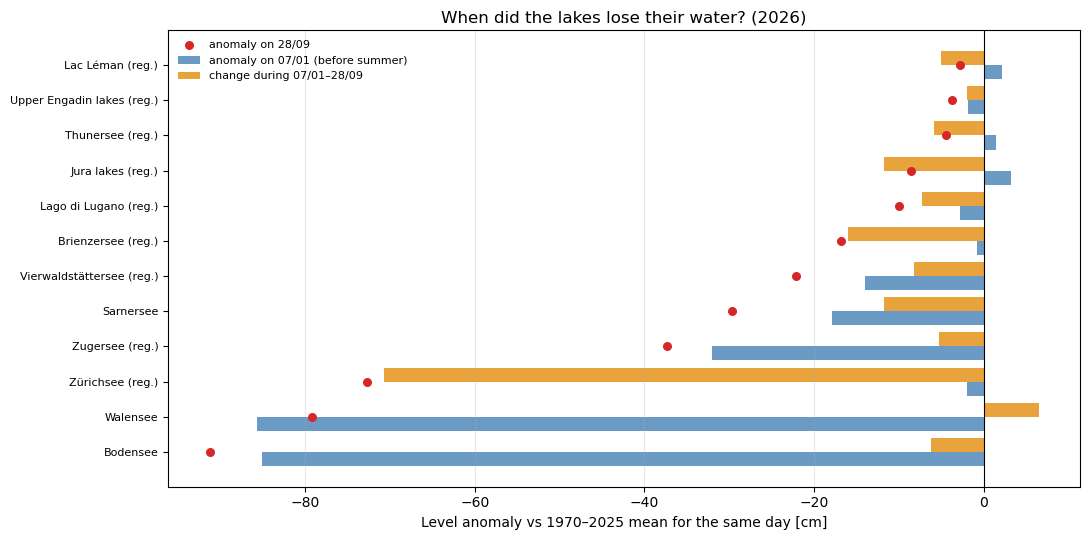

,anom_start_cm,anom_summer_cm,anom_end_cm,inflow_deficit_m3s,share_passed_downstream_pct
system,,,,,
Bodensee,-85.1,-6.2,-91.3,295.9,99.4
Walensee,-85.7,6.5,-79.2,44.8,100.7
Zürichsee,-2.0,-70.7,-72.7,77.0,89.8
Zugersee,-32.1,-5.3,-37.3,4.8,97.4
Sarnersee,-17.9,-11.8,-29.7,7.6,101.5
Vierwaldstättersee,-14.0,-8.2,-22.1,84.9,100.6
Brienzersee,-0.8,-16.0,-16.8,10.9,97.2
Lago di Lugano,-2.7,-7.3,-10.0,8.6,94.4
Jura lakes,3.2,-11.8,-8.6,112.0,96.7


In [11]:
n_days = (pd.Timestamp(CURRENT_YEAR, LAST_DAY.month, LAST_DAY.day) - pd.Timestamp(CURRENT_YEAR, m0, d0)).days + 1
rows = []
for name in comp.index:
    lev = DAILY[name]["level"]
    clim = climatology(lev)["mean"]
    t0, t1 = pd.Timestamp(CURRENT_YEAR, m0, d0), pd.Timestamp(CURRENT_YEAR, LAST_DAY.month, LAST_DAY.day)
    a0 = lev[t0] - clim[to_ref(pd.DatetimeIndex([t0]))[0]]
    a1 = lev[t1] - clim[to_ref(pd.DatetimeIndex([t1]))[0]]
    wm = WIN[name]
    ref = wm.loc[CLIM_START_YEAR:CLIM_END_YEAR].mean()
    cur = wm.loc[CURRENT_YEAR]
    deficit, downstream = ref["qin"] - cur["qin"], ref["qout"] - cur["qout"]
    rows.append({"system": name, "anom_start_cm": 100 * a0, "anom_summer_cm": 100 * (a1 - a0),
                 "anom_end_cm": 100 * a1, "inflow_deficit_m3s": deficit,
                 "share_passed_downstream_pct": 100 * downstream / deficit})
timing = pd.DataFrame(rows).set_index("system").sort_values("anom_end_cm")

fig, ax = plt.subplots(figsize=(11, 5.5))
y = np.arange(len(timing))
ax.barh(y - 0.2, timing["anom_start_cm"], height=0.4, color=C_STD, label=f"anomaly on {m0:02d}/{d0:02d} (before summer)")
ax.barh(y + 0.2, timing["anom_summer_cm"], height=0.4, color=C_STORE, label=f"change during {m0:02d}/{d0:02d}–{LAST_DAY:%d/%m}")
ax.scatter(timing["anom_end_cm"], y, color=C_CUR, zorder=3, s=30, label=f"anomaly on {LAST_DAY:%d/%m}")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y, [n + ("" if n in UNREGULATED else " (reg.)") for n in timing.index], fontsize=8)
ax.set_xlabel("Level anomaly vs 1970–2025 mean for the same day [cm]")
ax.set_title(f"When did the lakes lose their water? ({CURRENT_YEAR})")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "anomaly_timing.png", dpi=150)
plt.show()
timing.round(1)

# Evaporation

How much water did the lakes lose to the air this summer, and how does it compare with what the rivers brought?

**Method.** Alplakes provides the Simstrat lake model output (surface water temperature) through its API, but not the
heat fluxes. Evaporation is therefore recomputed with the bulk formula used by Simstrat for the latent heat flux
(Livingstone & Imboden, 1989):

$$Q_e = f(U)\,(e_s(T_w) - e_a), \qquad f(U) = 4.4 + 1.82\,U + 0.26\,(T_w - T_a) \quad [\mathrm{W\,m^{-2}\,hPa^{-1}}]$$

$$E = Q_e / (\rho_w L_v)$$

* $T_w$: daily mean Simstrat water temperature at 1 m (Alplakes API),
* $T_a$, $e_a$, $U$, $p$: daily mean air temperature, vapour pressure, 10 m wind speed and pressure at a nearby
  MeteoSwiss station (lakeside where possible),
* $e_s$: saturation vapour pressure (Magnus formula, pressure correction after Gill 1982).

Daily means are used in a non-linear formula and the wind is measured on land, so the absolute values are uncertain
(roughly ±30 %); the comparison between years and lakes is more robust.

In [12]:
SIMSTRAT_URL = "https://alplakes-api.eawag.ch/simulations/1d/point/simstrat/{lake}/{start}/{end}/1"
SIMSTRAT_DIR = DATA_DIR / "simstrat"
SIMSTRAT_DIR.mkdir(exist_ok=True)
METEO_DIR = DATA_DIR / "meteoswiss"
METEO_DIR.mkdir(exist_ok=True)
EVAP_NORM = (1991, 2020)
SIMSTRAT_START = 1981     # first summer fetched from Simstrat (surface temperature history)
END_MD = (REPORT_END.month, REPORT_END.day) if REPORT_END is not None else (LAST_DAY.month, LAST_DAY.day)

# lake (name in the FOEN VECTOR25 layer) -> (Simstrat lake key on Alplakes, MeteoSwiss station)
EVAP_LAKES = {
    "Le Léman": ("geneva", "PUY"), "Brienzer See": ("brienz", "INT"), "Thuner See": ("thun", "THU"),
    "Vierwaldstättersee": ("lucernekreuztrichterandvitznauerbecken", "LUZ"), "Zuger See": ("zug", "CHZ"),
    "Walensee": ("walensee", "GLA"), "Zürichsee": ("lowerzurich", "WAE"), "Bodensee": ("upperconstance", "GUT"),
    "Untersee": ("lowerconstance", "GUT"), "Sempacher See": ("sempach", "LUZ"), "Sarnersee": ("sarnen", "GIH"),
    "Lago di Lugano": ("upperlugano", "LUG"), "Lac de Neuchâtel": ("neuchatel", "NEU"),
    "Bieler See": ("biel", "CRM"), "Lac de Morat": ("murten", "PAY"), "Lej da Segl": ("sils", "SIA"),
    "Lej da Silvaplauna": ("silvaplana", "SIA"), "Lej da S. Murezzan": ("stmoritz", "SAM"),
    "Hallwiler See": ("hallwil", "BUS"), "Baldegger See": ("baldegg", "LUZ"), "Ägerisee": ("aegeri", "CHZ"),
    "Lauerzer See": ("lauerz", "ALT"), "Lac de Joux": ("joux", "BIE"), "Lago Maggiore": ("maggiore", "OTL"),
}
SHORT = {"Le Léman": "Geneva", "Brienzer See": "Brienz", "Thuner See": "Thun", "Vierwaldstättersee": "Lucerne",
         "Zuger See": "Zug", "Walensee": "Walensee", "Zürichsee": "Zurich", "Bodensee": "Constance",
         "Untersee": "Untersee", "Sempacher See": "Sempach", "Sarnersee": "Sarnen", "Lago di Lugano": "Lugano",
         "Lac de Neuchâtel": "Neuchâtel", "Bieler See": "Biel", "Lac de Morat": "Murten", "Lej da Segl": "Sils",
         "Lej da Silvaplauna": "Silvaplana", "Lej da S. Murezzan": "St. Moritz", "Hallwiler See": "Hallwil",
         "Baldegger See": "Baldegg", "Ägerisee": "Ägeri", "Lauerzer See": "Lauerz", "Lac de Joux": "Joux",
         "Lago Maggiore": "Maggiore"}

simstrat_meta = {l["name"]: l for l in
                 requests.get("https://alplakes-api.eawag.ch/simulations/1d/metadata", timeout=120).json()[0]["lakes"]}

def simstrat_summer(key):
    """Daily Simstrat water temperature at 1 m for 1 July to END_MD of every year, cached per lake."""
    path = SIMSTRAT_DIR / f"{key}_T1m_summer.csv"
    have = pd.read_csv(path, index_col="date", parse_dates=["date"])["T"] if path.exists() else pd.Series(dtype=float, index=pd.DatetimeIndex([], name="date"))
    have.index = pd.DatetimeIndex(pd.to_datetime(have.index), name="date")
    first = max(SIMSTRAT_START, pd.Timestamp(simstrat_meta[key]["start_date"]).year)
    new = []
    for y in range(first, CURRENT_YEAR + 1):
        if y < CURRENT_YEAR and (have.index.year == y).any():
            continue
        start, end = f"{y}07010000", f"{y}{END_MD[0]:02d}{END_MD[1]:02d}2300"
        for attempt in range(6):
            try:
                r = requests.get(SIMSTRAT_URL.format(lake=key, start=start, end=end),
                                 params={"resample": "daily", "variables": "T"}, timeout=120)
                if r.status_code == 200:
                    j = r.json()
                    idx = pd.to_datetime(j["time"]).tz_convert(None).normalize()
                    new.append(pd.Series(j["variables"]["T"]["data"], index=idx, dtype=float))
                    break
                if r.status_code in (400, 404):      # year not available for this lake
                    break
            except (requests.RequestException, ValueError):
                pass
            time.sleep(3 * 2 ** attempt)             # throttled or transient error: back off and retry
    s = pd.concat([have[have.index.year < CURRENT_YEAR]] + new) if new else have
    s = s[~s.index.duplicated(keep="last")].sort_index().rename("T")
    s.index.name = "date"
    s.to_frame().to_csv(path)
    return s

METEO_COLS = ["tre200d0", "pva200d0", "fkl010d0", "prestad0", "rre150d0"]
def meteo_daily(abbr):
    s = abbr.lower()
    frames = []
    for kind in ["historical", "recent"]:
        path = METEO_DIR / f"{s}_d_{kind}.csv"
        if kind == "recent" or not path.exists():
            path.write_bytes(requests.get(
                f"https://data.geo.admin.ch/ch.meteoschweiz.ogd-smn/{s}/ogd-smn_{s}_d_{kind}.csv", timeout=300).content)
        frames.append(pd.read_csv(path, sep=";", encoding="latin1", usecols=["reference_timestamp"] + METEO_COLS))
    df = pd.concat(frames)
    df["date"] = pd.to_datetime(df["reference_timestamp"], format="%d.%m.%Y %H:%M")
    df = df.drop_duplicates("date", keep="last").set_index("date").sort_index()[METEO_COLS]
    return df[:REPORT_END] if REPORT_END is not None else df

keys = sorted({k for k, _ in EVAP_LAKES.values()})
stations = sorted({s for _, s in EVAP_LAKES.values()})
with ThreadPoolExecutor(2) as pool:
    TW = dict(zip(keys, pool.map(simstrat_summer, keys)))
    MET = dict(zip(stations, pool.map(meteo_daily, stations)))
print({k: f"{v.index.year.min()}–{v.index.year.max()}" for k, v in TW.items()})

{'aegeri': '2012–2026', 'baldegg': '1981–2026', 'biel': '1981–2026', 'brienz': '1981–2026', 'geneva': '1981–2026', 'hallwil': '1981–2026', 'joux': '2010–2026', 'lauerz': '1981–2026', 'lowerconstance': '1981–2026', 'lowerzurich': '1981–2026', 'lucernekreuztrichterandvitznauerbecken': '1981–2026', 'maggiore': '1981–2026', 'murten': '1981–2026', 'neuchatel': '1981–2026', 'sarnen': '1981–2026', 'sempach': '1981–2026', 'sils': '2014–2026', 'silvaplana': '2014–2026', 'stmoritz': '1981–2026', 'thun': '1981–2026', 'upperconstance': '1981–2026', 'upperlugano': '1981–2026', 'walensee': '1981–2026', 'zug': '1981–2026'}


In [13]:
def esat(T):
    return 6.112 * np.exp(17.62 * T / (243.12 + T))            # hPa, Magnus (WMO)

def evaporation_mm_day(Tw, Ta, ea, U, p):
    f = np.maximum(4.4 + 1.82 * U + 0.26 * (Tw - Ta), 0)        # W m-2 hPa-1, Livingstone & Imboden (1989)
    es = esat(Tw) * (1.0007 + 3.46e-6 * p)                       # Gill (1982) pressure correction
    Qe = f * (es - ea)                                           # W m-2, positive = loss from the lake
    return Qe / (1000 * 2.47e6) * 86400 * 1000                   # mm/day

def summer_window(s, y):
    return s.loc[pd.Timestamp(y, 7, 1):pd.Timestamp(y, *END_MD)]

n_window = (pd.Timestamp(2001, *END_MD) - pd.Timestamp(2001, 7, 1)).days + 1
rows = []
for lake, (key, st) in EVAP_LAKES.items():
    tw, met = TW[key], MET[st]
    for y in sorted(set(tw.index.year)):
        if y < EVAP_NORM[0]:                      # evaporation statistics from 1991 on
            continue
        t = summer_window(tw, y)
        m = met.reindex(t.index)
        e = evaporation_mm_day(t, m["tre200d0"], m["pva200d0"], m["fkl010d0"], m["prestad0"])
        if e.notna().sum() < 0.9 * n_window or m["rre150d0"].notna().sum() < 0.9 * n_window:
            continue
        rows.append({"lake": lake, "year": y, "E_mm_day": e.mean(), "P_mm_day": m["rre150d0"].mean(),
                     "Tw": t.mean()})
evap_years = pd.DataFrame(rows)

def normal(df, col):
    ref = df[(df["year"] >= EVAP_NORM[0]) & (df["year"] <= EVAP_NORM[1])]
    if ref["year"].nunique() < 10:                     # short Simstrat record: use all years before the current one
        ref = df[df["year"] < CURRENT_YEAR]
    return ref[col].mean(), ref["year"].min(), ref["year"].max()

rows = []
for lake, g in evap_years.groupby("lake"):
    if CURRENT_YEAR not in set(g["year"]):
        continue
    cur = g[g["year"] == CURRENT_YEAR].iloc[0]
    e_n, y0, y1 = normal(g, "E_mm_day")
    tw_n, _, _ = normal(g, "Tw")
    rows.append({"lake": lake, "short": SHORT[lake], "E_2026_cm": cur["E_mm_day"] * n_window / 10,
                 "E_normal_cm": e_n * n_window / 10, "extra_cm": (cur["E_mm_day"] - e_n) * n_window / 10,
                 "E_pct_of_normal": 100 * cur["E_mm_day"] / e_n, "Tw_2026": cur["Tw"], "Tw_anom": cur["Tw"] - tw_n,
                 "rank_high": int((g["E_mm_day"] >= cur["E_mm_day"]).sum()), "n_years": g["year"].nunique(),
                 "normal_period": f"{y0}–{y1}"})
evap = pd.DataFrame(rows).set_index("lake").sort_values("E_2026_cm")
print(f"Window 1 Jul – {END_MD[1]:02d}.{END_MD[0]:02d} ({n_window} days)")
evap.round(1)

Window 1 Jul – 28.09 (90 days)


,short,E_2026_cm,E_normal_cm,extra_cm,E_pct_of_normal,Tw_2026,Tw_anom,rank_high,n_years,normal_period
lake,,,,,,,,,,
Brienzer See,Brienz,18.1,8.0,10.1,225.9,19.2,3.3,1,35,1991–2020
Lej da S. Murezzan,St. Moritz,28.5,23.5,5.0,121.4,16.5,1.8,3,36,1991–2020
Sarnersee,Sarnen,28.7,19.7,9.0,145.9,23.3,2.6,1,16,2011–2020
Thuner See,Thun,29.2,17.2,12.0,170.1,22.0,2.6,1,14,2013–2025
Vierwaldstättersee,Lucerne,31.3,14.7,16.6,213.2,22.9,4.2,1,36,1991–2020
Lej da Silvaplauna,Silvaplana,32.7,25.8,6.9,127.0,17.4,2.2,2,13,2014–2025
Lej da Segl,Sils,33.6,28.1,5.5,119.6,17.5,1.9,2,13,2014–2025
Walensee,Walensee,33.9,17.3,16.5,195.5,22.3,4.1,1,36,1991–2020
Lago Maggiore,Maggiore,37.9,24.6,13.4,154.4,25.1,3.3,1,36,1991–2020


## Evaporation in the water budget of the 13 lake systems

The reconstructed inflow $Q_{in}$ of the first part is a *net* inflow: rivers + rain on the lake − evaporation.
With evaporation $E$ and precipitation $P$ on the lake surface (station precipitation), the water brought by the rivers is

$$R = Q_{in} + (E - P)\,A$$

and the share of evaporation in the total water input is $E\,A / (R + P\,A)$.

In [14]:
# FOEN station -> lake name in EVAP_LAKES (the Bodensee gauges refer to Obersee and Untersee)
STATION_LAKE = {no: VEC25[no] for no in VEC25}
STATION_LAKE["2043"] = "Untersee"

rows = []
for name, s in SYSTEMS.items():
    wm = WIN[name]
    if CURRENT_YEAR not in wm.index:
        continue
    qin_26 = wm.loc[CURRENT_YEAR, "qin"]
    qin_n = wm.loc[CLIM_START_YEAR:CLIM_END_YEAR, "qin"].mean()
    E26 = En = P26 = Pn = 0.0
    for no, a_km2 in s["levels"].items():
        g = evap_years[evap_years["lake"] == STATION_LAKE[no]]
        a = a_km2 * 1e6 / 86400 / 1000                           # mm/day -> m³/s
        E26 += a * g.loc[g["year"] == CURRENT_YEAR, "E_mm_day"].iloc[0]
        P26 += a * g.loc[g["year"] == CURRENT_YEAR, "P_mm_day"].iloc[0]
        En += a * normal(g, "E_mm_day")[0]
        Pn += a * normal(g, "P_mm_day")[0]
    R26, Rn = qin_26 + E26 - P26, qin_n + En - Pn
    rows.append({"system": name, "E_2026_m3s": E26, "E_normal_m3s": En, "rivers_2026_m3s": R26,
                 "rivers_normal_m3s": Rn, "share_2026_pct": 100 * E26 / (R26 + P26),
                 "share_normal_pct": 100 * En / (Rn + Pn)})
budget = pd.DataFrame(rows).set_index("system").sort_values("share_2026_pct")
budget.round(1)

,E_2026_m3s,E_normal_m3s,rivers_2026_m3s,rivers_normal_m3s,share_2026_pct,share_normal_pct
system,,,,,,
Brienzersee,0.7,0.3,91.4,101.4,0.8,0.3
Thunersee,1.8,1.1,117.8,166.3,1.5,0.6
Walensee,1.0,0.5,19.5,62.9,5.2,0.8
Upper Engadin lakes,0.3,0.3,5.4,9.1,6.0,2.9
Vierwaldstättersee,4.6,2.1,65.9,146.0,6.6,1.4
Sarnersee,0.3,0.2,3.0,10.3,8.8,1.8
Jura lakes,16.2,10.9,153.2,256.0,10.2,4.1
Lac Léman,31.1,18.8,238.1,299.5,12.4,5.8
Bodensee,27.6,17.2,132.3,409.5,19.1,4.0


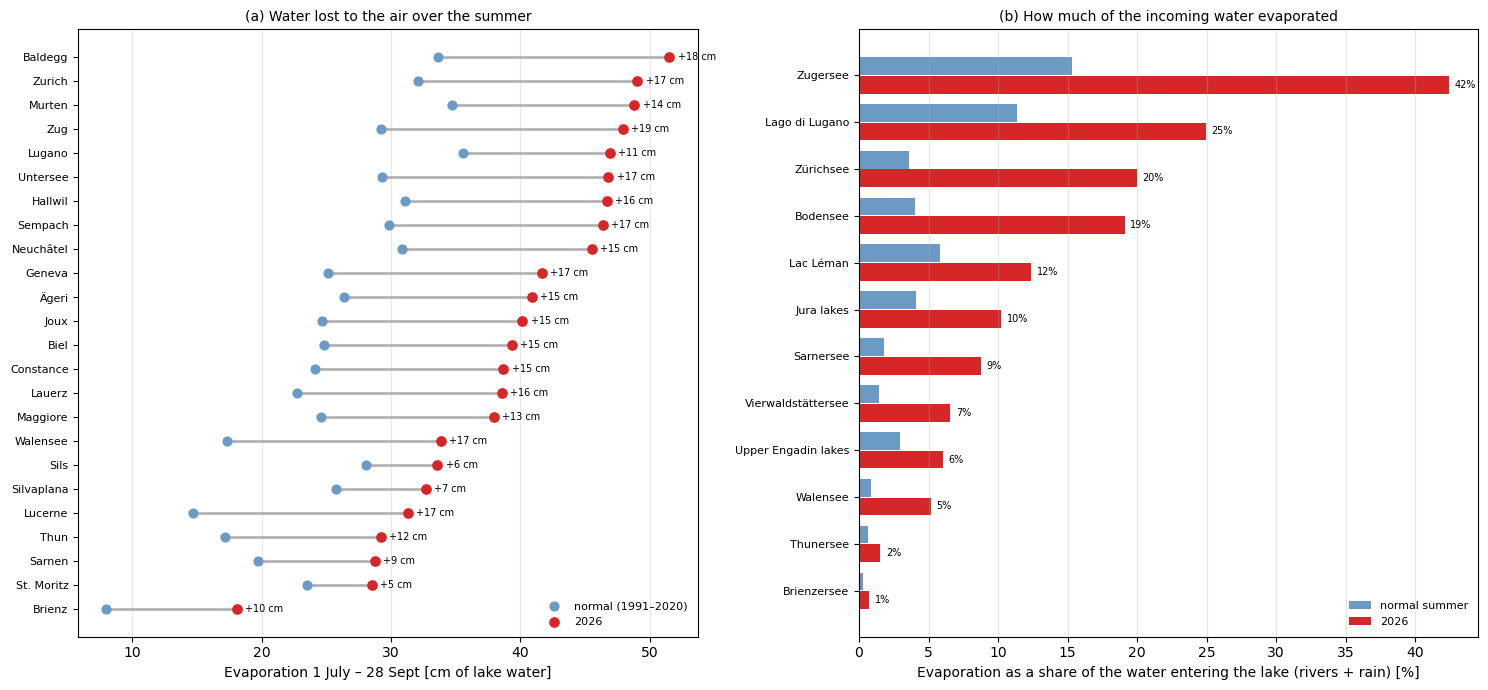

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 1]})

ax = axes[0]
d = evap.sort_values("E_2026_cm")
y = np.arange(len(d))
ax.hlines(y, d["E_normal_cm"], d["E_2026_cm"], color="0.7", lw=2, zorder=1)
ax.scatter(d["E_normal_cm"], y, color=C_STD, s=40, zorder=2, label=f"normal ({EVAP_NORM[0]}–{EVAP_NORM[1]})")
ax.scatter(d["E_2026_cm"], y, color=C_CUR, s=45, zorder=3, label=str(CURRENT_YEAR))
for yi, (_, r) in zip(y, d.iterrows()):
    ax.annotate(f"+{r['extra_cm']:.0f} cm" if r["extra_cm"] >= 0 else f"{r['extra_cm']:.0f} cm",
                (r["E_2026_cm"], yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=7)
ax.set_yticks(y, d["short"], fontsize=8)
ax.set_xlabel(f"Evaporation 1 July – {END_MD[1]} Sept [cm of lake water]")
ax.set_title("(a) Water lost to the air over the summer", fontsize=10)
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.3)

ax = axes[1]
b = budget.sort_values("share_2026_pct")
y = np.arange(len(b))
ax.barh(y + 0.2, b["share_normal_pct"], height=0.38, color=C_STD, label=f"normal summer")
ax.barh(y - 0.2, b["share_2026_pct"], height=0.38, color=C_CUR, label=str(CURRENT_YEAR))
for yi, v in zip(y, b["share_2026_pct"]):
    ax.annotate(f"{v:.0f}%", (v, yi - 0.2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=7)
ax.set_yticks(y, b.index, fontsize=8)
ax.set_xlabel("Evaporation as a share of the water entering the lake (rivers + rain) [%]")
ax.set_title("(b) How much of the incoming water evaporated", fontsize=10)
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "evaporation.png", dpi=150)
plt.show()

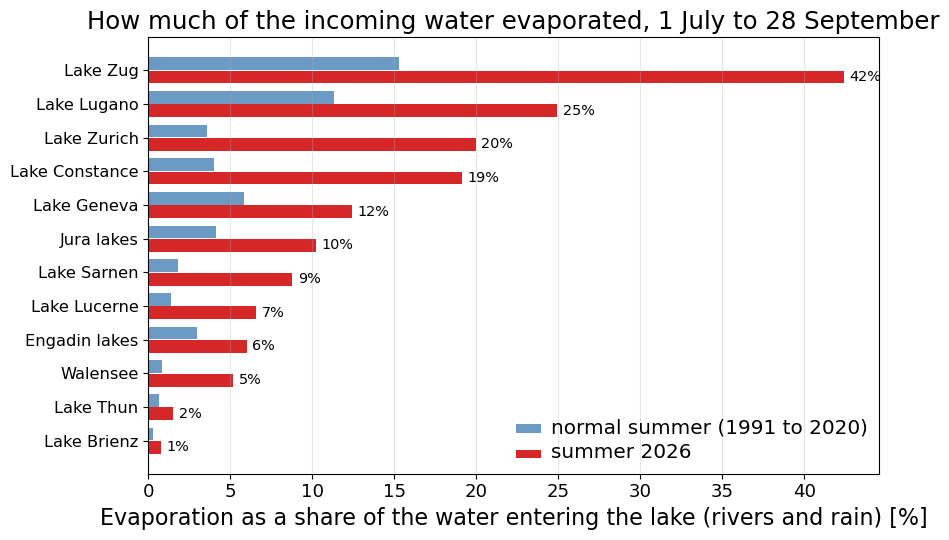

In [16]:
b = budget.sort_values("share_2026_pct")
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(b))
ax.barh(y + 0.2, b["share_normal_pct"], height=0.38, color=C_STD, label=f"normal summer ({EVAP_NORM[0]} to {EVAP_NORM[1]})")
ax.barh(y - 0.2, b["share_2026_pct"], height=0.38, color=C_CUR, label=f"summer {CURRENT_YEAR}")
for yi, v in zip(y, b["share_2026_pct"]):
    ax.annotate(f"{v:.0f}%", (v, yi - 0.2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_yticks(y, [SYS_EN.get(n, n) for n in b.index], fontsize=9)
ax.set_xlabel("Evaporation as a share of the water entering the lake (rivers and rain) [%]")
ax.set_title(f"How much of the incoming water evaporated, 1 July to {END_MD[1]} September", fontsize=11)
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(REPORT_FIG_DIR / "evaporation_share.png", dpi=150)
plt.show()

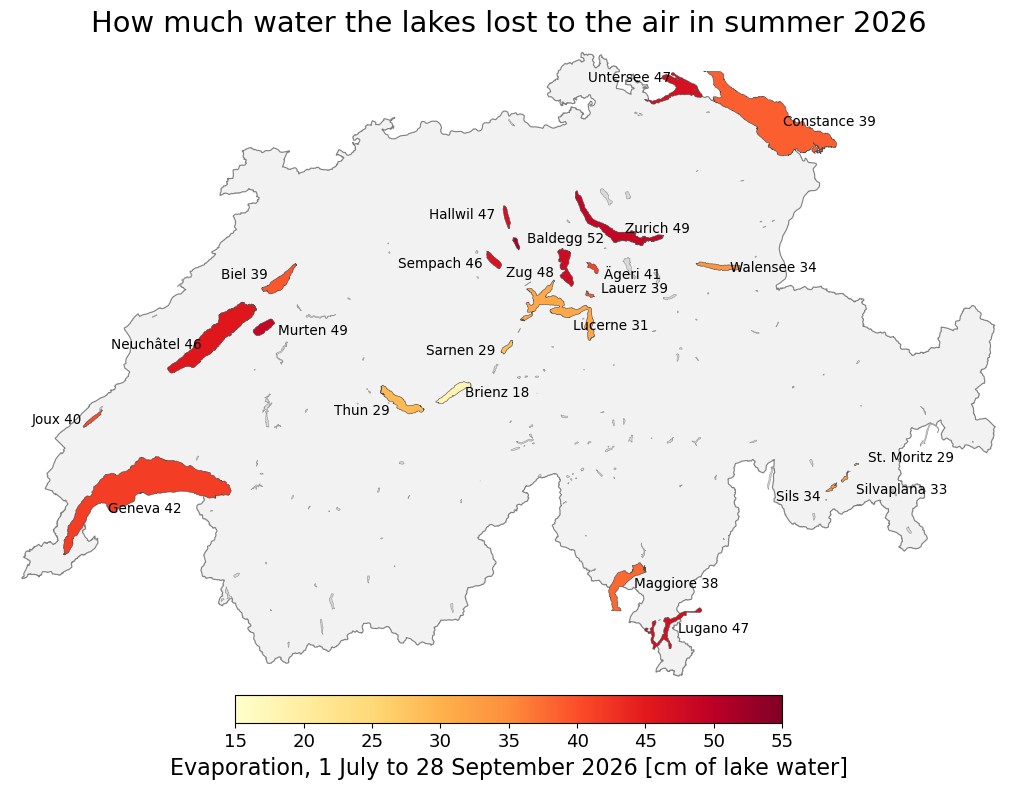

In [17]:
import matplotlib as mpl

border = json.loads((DATA_DIR / "ch_border.geojson").read_text())["feature"]["geometry"]["coordinates"]
lake_layer = load_lake_layer()

def rings(f):
    g = f["geometry"]
    return [np.array(p[0]) for p in (g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]])]

def centroid(ring):
    x, yv = ring[:, 0], ring[:, 1]
    a = x * np.roll(yv, -1) - np.roll(x, -1) * yv
    A = a.sum() / 2
    return (np.sum((x + np.roll(x, -1)) * a) / (6 * A), np.sum((yv + np.roll(yv, -1)) * a) / (6 * A)), abs(A)

vals = evap["E_2026_cm"]
norm_c = mpl.colors.Normalize(vmin=np.floor(vals.min() / 5) * 5, vmax=np.ceil(vals.max() / 5) * 5)
cmap = mpl.cm.YlOrRd
OFFS = {"Biel": (-8, 6, "right"), "Murten": (10, -2, "left"), "Neuchâtel": (-10, -6, "right"),
        "Sils": (-8, -6, "right"), "Silvaplana": (8, -8, "left"), "St. Moritz": (8, 5, "left"),
        "Sarnen": (-8, -2, "right"), "Sempach": (-8, -2, "right"), "Hallwil": (-8, 2, "right"),
        "Baldegg": (8, 4, "left"), "Zug": (-8, -4, "right"), "Ägeri": (8, -4, "left"), "Lauerz": (8, 5, "left"),
        "Lucerne": (10, -12, "left"), "Thun": (-8, -6, "right"), "Joux": (-8, 0, "right"),
        "Geneva": (0, -14, "center"), "Untersee": (-6, 8, "right")}

fig, ax = plt.subplots(figsize=(12, 8))
for poly in border:
    r = np.array(poly[0])
    ax.fill(r[:, 0], r[:, 1], color="#f2f2f2", zorder=0)
    ax.plot(r[:, 0], r[:, 1], color="0.5", lw=0.8, zorder=1)
for f in lake_layer:
    name = f["properties"]["name"]
    color = cmap(norm_c(vals[name])) if name in vals.index else "#d9d9d9"
    for r in rings(f):
        ax.fill(r[:, 0], r[:, 1], color=color, ec="0.3" if name in vals.index else "0.6", lw=0.4, zorder=2)
for name in vals.index:
    feats = [f for f in lake_layer if f["properties"]["name"] == name]
    if not feats:
        continue
    (cx, cy), _ = max((centroid(r) for f in feats for r in rings(f)), key=lambda t: t[1])
    lab = SHORT[name]
    dx, dy, ha = OFFS.get(lab, (8, 0, "left"))
    ax.annotate(f"{lab} {vals[name]:.0f}", (cx, cy), xytext=(dx, dy), textcoords="offset points",
                fontsize=7.5, ha=ha, va="center", zorder=5)
sm = mpl.cm.ScalarMappable(norm=norm_c, cmap=cmap)
cb = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.04, pad=0.02, shrink=0.5)
cb.set_label(f"Evaporation, 1 July to {END_MD[1]} September {CURRENT_YEAR} [cm of lake water]")
ax.set_xlim(5.9, 10.55)
ax.set_ylim(45.8, 47.85)
ax.set_aspect(1 / np.cos(np.radians(46.8)))
ax.set_xticks([])
ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title(f"How much water the lakes lost to the air in summer {CURRENT_YEAR}", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "evaporation_map.png", dpi=150)
plt.show()

## Surface temperature

Summer (1 July to the report day) mean of the daily Simstrat water temperature at 1 m, every year since 1981
(or the start of the Simstrat run). Anomalies are relative to 1991–2020 (or the available years before the current one
for lakes with a shorter run). The trend is a least squares fit over all years before the current one.

In [18]:
rows = []
for lake, (key, _) in EVAP_LAKES.items():
    tw = TW[key]
    for y in sorted(set(tw.index.year)):
        t = summer_window(tw, y)
        if t.notna().sum() >= 0.9 * n_window:
            rows.append({"lake": lake, "year": y, "Tw": t.mean(), "Tw_max": t.max()})
tw_years = pd.DataFrame(rows)

rows = []
for lake, g in tw_years.groupby("lake"):
    g = g.set_index("year")
    if CURRENT_YEAR not in g.index:
        continue
    past = g.loc[g.index < CURRENT_YEAR]
    ref = past.loc[EVAP_NORM[0]:EVAP_NORM[1]]
    if len(ref) < 10:
        ref = past
    slope = np.polyfit(past.index, past["Tw"], 1)[0] * 10 if len(past) >= 10 else np.nan
    rows.append({"lake": lake, "short": SHORT[lake], "Tw_2026": g.loc[CURRENT_YEAR, "Tw"],
                 "Tw_normal": ref["Tw"].mean(), "anomaly": g.loc[CURRENT_YEAR, "Tw"] - ref["Tw"].mean(),
                 "rank_warm": int((g["Tw"] >= g.loc[CURRENT_YEAR, "Tw"]).sum()), "n_years": len(g),
                 "first_year": g.index.min(), "prev_record": past["Tw"].idxmax(),
                 "margin_over_record": g.loc[CURRENT_YEAR, "Tw"] - past["Tw"].max(),
                 "Tmax_2026": g.loc[CURRENT_YEAR, "Tw_max"], "Tmax_before": past["Tw_max"].max(),
                 "trend_C_per_decade": slope})
tw_stats = pd.DataFrame(rows).set_index("lake").sort_values("anomaly")
print(f"record warm summer at {int((tw_stats['rank_warm'] == 1).sum())} of {len(tw_stats)} lakes; "
      f"median anomaly {tw_stats['anomaly'].median():.1f} °C; median trend {tw_stats['trend_C_per_decade'].median():.2f} °C/decade")
tw_stats.round(2)

record warm summer at 23 of 24 lakes; median anomaly 3.2 °C; median trend 0.63 °C/decade


,short,Tw_2026,Tw_normal,anomaly,rank_warm,n_years,first_year,prev_record,margin_over_record,Tmax_2026,Tmax_before,trend_C_per_decade
lake,,,,,,,,,,,,
Lej da S. Murezzan,St. Moritz,16.49,14.71,1.77,1,46,1981,2022,0.04,18.22,18.60,0.64
Lej da Segl,Sils,17.54,15.68,1.85,1,13,2014,2022,0.60,19.52,19.47,1.38
Lej da Silvaplauna,Silvaplana,17.36,15.19,2.18,1,13,2014,2022,0.82,19.46,19.02,1.48
Sarnersee,Sarnen,23.31,20.98,2.33,2,46,1981,2003,-0.23,24.96,26.25,0.22
Ägerisee,Ägeri,24.02,21.59,2.43,1,15,2012,2022,0.71,26.51,27.75,1.57
Bodensee,Constance,23.07,20.37,2.70,1,46,1981,2003,0.48,25.24,26.23,0.26
Lac de Morat,Murten,25.10,22.18,2.93,1,46,1981,2018,0.89,27.66,28.46,0.48
Untersee,Untersee,24.33,21.40,2.93,1,46,1981,2018,0.76,26.99,27.60,0.53
Lac de Neuchâtel,Neuchâtel,23.80,20.85,2.95,1,46,1981,2018,1.03,25.86,26.14,0.51


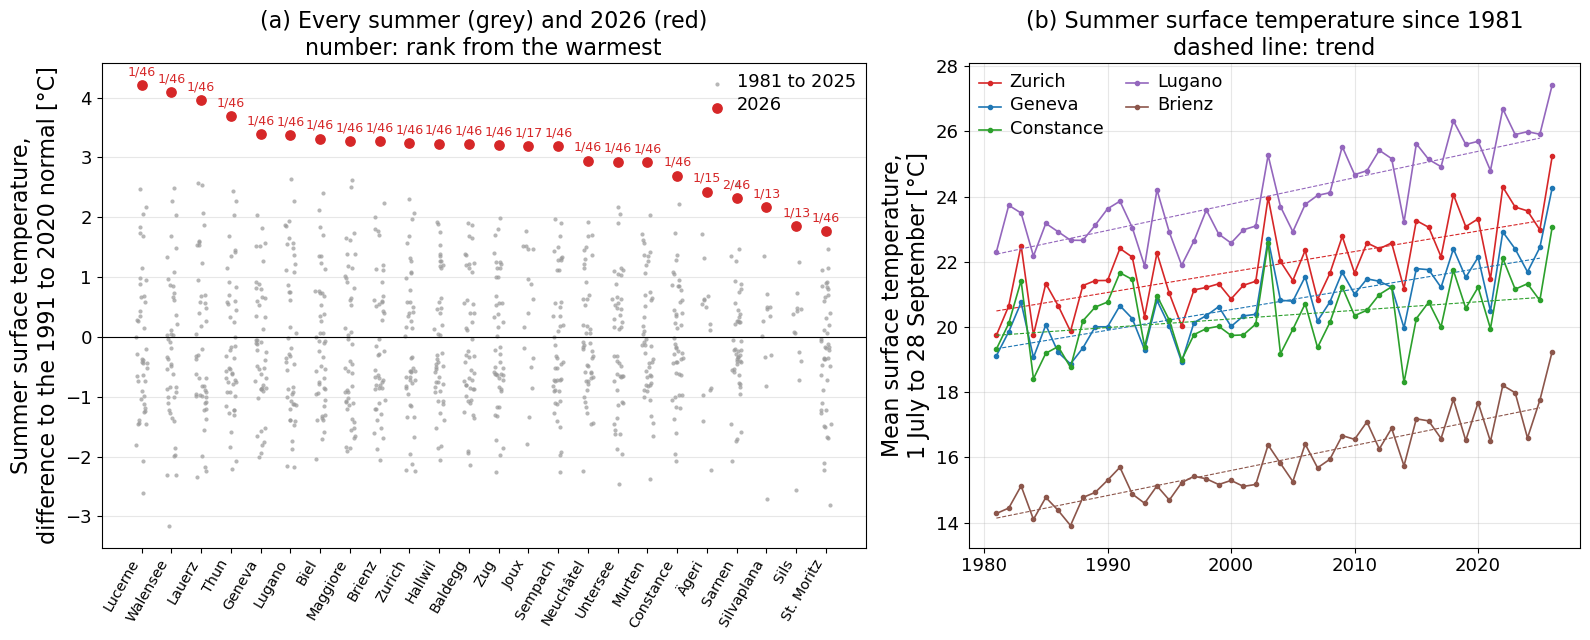

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
order = tw_stats.sort_values("anomaly", ascending=False).index
rng = np.random.default_rng(0)
for i, lake in enumerate(order):
    g = tw_years[tw_years["lake"] == lake].set_index("year")["Tw"]
    ref_mean = tw_stats.loc[lake, "Tw_normal"]
    past = g[g.index < CURRENT_YEAR] - ref_mean
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(past)), past, s=9, color="0.6", alpha=0.7, lw=0,
               label=f"{SIMSTRAT_START} to {CURRENT_YEAR - 1}" if i == 0 else None)
    a = tw_stats.loc[lake, "anomaly"]
    ax.scatter(i, a, s=45, color=C_CUR, zorder=3, label=str(CURRENT_YEAR) if i == 0 else None)
    ax.annotate(f"{tw_stats.loc[lake, 'rank_warm']}/{tw_stats.loc[lake, 'n_years']}", (i, a), xytext=(0, 7),
                textcoords="offset points", ha="center", fontsize=7, color=C_CUR)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(order)), [SHORT[l] for l in order], rotation=60, ha="right", fontsize=8)
ax.set_ylabel(f"Summer surface temperature,\ndifference to the {EVAP_NORM[0]} to {EVAP_NORM[1]} normal [°C]")
ax.set_title(f"(a) Every summer (grey) and {CURRENT_YEAR} (red)\nnumber: rank from the warmest", fontsize=10)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper right", fontsize=8)

ax = axes[1]
SHOW = {"Zürichsee": "#d62728", "Le Léman": "#1f77b4", "Bodensee": "#2ca02c", "Lago di Lugano": "#9467bd",
        "Brienzer See": "#8c564b"}
for lake, color in SHOW.items():
    g = tw_years[tw_years["lake"] == lake].set_index("year")["Tw"]
    ax.plot(g.index, g.values, "-o", ms=3, lw=1.2, color=color, label=SHORT[lake])
    past = g[g.index < CURRENT_YEAR]
    k, b = np.polyfit(past.index, past.values, 1)
    ax.plot(past.index, k * past.index + b, "--", color=color, lw=0.8)
ax.set_ylabel("Mean surface temperature,\n1 July to 28 September [°C]")
ax.set_title(f"(b) Summer surface temperature since {SIMSTRAT_START}\ndashed line: trend", fontsize=10)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "surface_temperature.png", dpi=150)
plt.show()